# Lecture 20

## Downloading Data From Kaggle

You are likely going to be able to download the data for your kaggle competition by clicking the download button on data page. Note that since most of you are using WSL, and your browser is running in Windows, you should either copy the data into the virtual machine or read the Windows disk via the virtual machine. If the data file(s) are CSV, look at the contents of the file, as we have done in previous lectures and try to answer:
 
* Is the first row the column names?
* Comma separated?
* Number of rows
* Number of columns
* Size on disk    

For lab this Friday, you are required to download the data and load it up into a Pandas dataframe so we can take a look.

### Kaggle API

A better way to get your data from Kaggle is to use their API. You are not required to do this. But in case you would like to, follow instructions on how to install the [kaggle API](https://www.kaggle.com/docs/api) in your virtual machine. You will need to also setup your PATH environment variable, which can be tricky.
    
## Playing with Tabular Data

A recent [interesting paper](https://arxiv.org/pdf/2207.08815.pdf) compared the performance of Machine Learning algorithms on large number of tabular datasets, illustrating that Boosted Decision Trees are preferred ML Algorithm on tabular data. The datasets have been currated into a [kaggle competition](https://www.kaggle.com/competitions/bench-tab-v1), and we are going to take a look at them.

I've downloaded the datasets via kaggle API and unzip it to find the following:

In [1]:
!ls Train

334_361110     335_361101     336_361074     336_361088     337_361070
334_361111     335_361102     336_361076     336_361279     337_361273
334_361113     335_361103     336_361077     336_361280     337_361274
334_361282     335_361104     336_361078     336_361281     337_361275
334_361283     335_361287     336_361079     337_361055     337_361276
334_361285     335_361288     336_361080     337_361060     337_361277
334_361286     335_361289     336_361081     337_361061     337_361278
335_361093     335_361291     336_361082     337_361062     dict_suit.json
335_361094     335_361292     336_361083     337_361063     dict_task.json
335_361096     335_361293     336_361084     337_361065     submission.csv
335_361097     335_361294     336_361085     337_361066
335_361098     336_361072     336_361086     337_361068
335_361099     336_361073     336_361087     337_361069


In [2]:
!ls Train/334_361110

attribute_names.json       data_train.parquet
categorical_indicator.json target_train.parquet
data_test.parquet


### The benchmark

The paper behind this data, Grinsztajn, Oyallon and Varoquaux (2022), *Why do tree-based models
still outperform deep learning on tabular data?*, asked which methods work best on medium-sized
tables of high-level features. The answer was **tree-based models**: random forests and, above all,
gradient-boosted trees. scikit-learn has them built in, and XGBoost has the same interface. A
**decision tree** is a sequence of yes/no cuts on single features; a **random forest** averages many
trees, each trained on a random part of the data; **boosting** trains small trees one after another,
each correcting the errors of those before it, and adds up their votes.

**Which method wins depends on the regime.** Deep networks learn their own features from
**low-level features** (raw measurements), but that takes a lot of data and a lot of computing. With
unlimited data and computing, a deep network will probably beat anything else. Most real problems are
not like that (in health science, for example, data is limited), and tabular data is usually the other
regime: not much data, and **high-level features**, quantities someone has already built or chosen.
There a boosted decision tree usually does better. Particle physics went through both regimes: for
about a decade physicists built features by hand (**feature engineering**) and fed them to boosted
decision trees, until the paper behind the SUSY dataset (Lab 7) showed that a deep network given the
low-level features did not need that step. Both findings are right for their kind of data. For your
own tabular project, boosted decision trees are the method to beat.

The authors took many very different datasets and **curated** them so they all look the same: the
same files, the same names, the same format. That is the idea of an interface from Chapter 4,
applied to data.

**Get data by command, not by clicking.** Your work has to be reproducible and documented. A
download command kept in the notebook (`wget`, `curl`, or the `kaggle` command-line tool) means you,
or anyone else, can get the data again. An **API** (application programming interface) is the set of
commands, with their arguments, that a service accepts: "the definition of my service". Kaggle's is a
**REST API**: each request is a URL you construct, and the reply is data, usually **JSON**, the
dictionary-like text format. The `kaggle` package wraps those requests in a **CLI** (command-line
interface) and a Python library, and authenticates with a key you keep in a file. The same holds for
any service, a language model's API included: calling it from code rather than clicking in an app is
what makes the work repeatable.

**Read the folder before the documentation.** The file names already tell the story:
`data_train` and `target_train` are the inputs and the answers (a **supervised** problem); `data_test` has no answers, because
that is what the competition scores. The first thing you will do with the training files is cut
them up yourself, so that you can judge your work without bias.

The data is in **Parquet**, a binary, column-by-column format that stores the column names and
types. pandas reads it as easily as CSV (it needs the `pyarrow` package), but you can't `cat` it.

Lets investigate the contents of some of these files:

In [3]:
!cat Train/dict_suit.json

{"334": [361110, 361111, 361113, 361282, 361283, 361285, 361286], "335": [361093, 361094, 361096, 361097, 361098, 361099, 361101, 361102, 361103, 361104, 361287, 361288, 361289, 361291, 361292, 361293, 361294], "336": [361072, 361073, 361074, 361076, 361077, 361078, 361079, 361080, 361081, 361082, 361083, 361084, 361085, 361086, 361087, 361088, 361279, 361280, 361281], "337": [361055, 361060, 361061, 361062, 361063, 361065, 361066, 361068, 361069, 361070, 361273, 361274, 361275, 361276, 361277, 361278]}

In [4]:
!cat Train/dict_task.json

{"336": {"features": "num", "target": "num"}, "337": {"features": "num", "target": "cat"}, "335": {"features": "num+cat", "target": "num"}, "334": {"features": "num+cat", "target": "cat"}}

In [5]:
import json
json.load(open("Train/dict_task.json","r"))

{'336': {'features': 'num', 'target': 'num'},
 '337': {'features': 'num', 'target': 'cat'},
 '335': {'features': 'num+cat', 'target': 'num'},
 '334': {'features': 'num+cat', 'target': 'cat'}}

In [6]:
datasets=json.load(open("Train/dict_suit.json","r"))

These json files seems to separate the datasets:

* 334: Classification with numerical and categorical inputs.
* 335: Regression with numerical and categorical inputs.
* 336: Regression with numerical inputs only.
* 337: Classification with numerical only.

Every dataset sits in it own directory, and contains the fillowing files:

In [7]:
!ls -lh Train/334_361110

total 2016
-rw-------@ 1 afarbin  staff    87B Apr  8 11:39 attribute_names.json
-rw-------@ 1 afarbin  staff    55B Apr  8 11:39 categorical_indicator.json
-rw-------@ 1 afarbin  staff   361K Apr  8 11:39 data_test.parquet
-rw-------@ 1 afarbin  staff   490K Apr  8 11:39 data_train.parquet
-rw-------@ 1 afarbin  staff   142K Apr  8 11:38 target_train.parquet


Clearly the data is in parquet format, which luckily Pandas reads. And it is separated between train and test, where the target variable is for the training dataset is also provided in another parquet file. We'll check on this later.

Lets look at each `json` file to see if we can figure out what they contain:

In [8]:
!cat Train/334_361110/attribute_names.json

["date", "day", "period", "nswprice", "nswdemand", "vicprice", "vicdemand", "transfer"]

Looks like the field names. Probably redundant info, since it'll probably be in the parquet file too.

In [9]:
!cat Train/334_361110/categorical_indicator.json

[false, true, false, false, false, false, false, false]

Looks like a list indicating the the inputs are categorical or numerical. Seems like info that would be useful, so lets load it up into a python list: 

In [10]:
cat_list = json.load(open("Train/334_361110/categorical_indicator.json","r"))
cat_list

[False, True, False, False, False, False, False, False]

Basic counting:

In [11]:
num_cat, num_not_cat = sum(cat_list), len(cat_list)-sum(cat_list)
num_cat, num_not_cat

(1, 7)

## Check

Lets do some checks on all of these data sets.

First thing, lets see if any of these datasets have missing values. I'll work out a way to test this on one file first:

In [12]:
import pandas as pd
df = pd.read_parquet("Train/334_361110/data_train.parquet")

In [13]:
df.isnull()

,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer
1027,False,False,False,False,False,False,False,False
28781,False,False,False,False,False,False,False,False
17825,False,False,False,False,False,False,False,False
33852,False,False,False,False,False,False,False,False
7502,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...
6265,False,False,False,False,False,False,False,False
11284,False,False,False,False,False,False,False,False
38158,False,False,False,False,False,False,False,False
860,False,False,False,False,False,False,False,False


So this should test if there are any null values:

In [14]:
import numpy as np
np.any(df.isnull())

np.False_

The shape of the `DataFrame` will tell me the number of datapoints and columns:

In [15]:
df.shape

(23084, 8)

A null is an empty field, which is not the same as zero. `df.isnull()` tests every element, and
`np.any` asks "is this true anywhere?".

Now lets look at target file:

In [16]:
df = pd.read_parquet("Train/334_361110/target_train.parquet")

In [17]:
df

,target
1027,0
28781,1
17825,0
33852,1
7502,0
...,...
6265,0
11284,0
38158,1
860,0


That's clearly a binary classification dataset. Lets look at a regression one:

In [18]:
df = pd.read_parquet("Train/336_361079/target_train.parquet")
df

,price
3032,10.614008
21981,12.385477
2094,10.768506
21574,9.615805
12850,10.292179
...,...
11964,10.322231
21575,10.518700
5390,10.566201
860,10.264687


0/1 targets mean binary classification. Targets that look like measurements mean regression.
`read_parquet` and `read_csv` give you the same kind of DataFrame: how the data is stored on disk is
separate from how you work with it.

Lets now look at every dataset and confirm some things. To determine if it's a classification or regression task, we can look at the target files:

In [19]:
!ls Train/*/target_train.parquet

Train/334_361110/target_train.parquet Train/336_361079/target_train.parquet
Train/334_361111/target_train.parquet Train/336_361080/target_train.parquet
Train/334_361113/target_train.parquet Train/336_361081/target_train.parquet
Train/334_361282/target_train.parquet Train/336_361082/target_train.parquet
Train/334_361283/target_train.parquet Train/336_361083/target_train.parquet
Train/334_361285/target_train.parquet Train/336_361084/target_train.parquet
Train/334_361286/target_train.parquet Train/336_361085/target_train.parquet
Train/335_361093/target_train.parquet Train/336_361086/target_train.parquet
Train/335_361094/target_train.parquet Train/336_361087/target_train.parquet
Train/335_361096/target_train.parquet Train/336_361088/target_train.parquet
Train/335_361097/target_train.parquet Train/336_361279/target_train.parquet
Train/335_361098/target_train.parquet Train/336_361280/target_train.parquet
Train/335_361099/target_train.parquet Train/336_361281/target_train.parquet
Train/335_36

Lets make a list of these filenames so we can open them up one by one:

In [20]:
import glob 
import numpy as np
target_files = sorted(glob.glob("Train/*/target_train.parquet"))  # Fixed 2026-10: sorted, so the order is the same on every computer
target_files

['Train/334_361110/target_train.parquet',
 'Train/334_361111/target_train.parquet',
 'Train/334_361113/target_train.parquet',
 'Train/334_361282/target_train.parquet',
 'Train/334_361283/target_train.parquet',
 'Train/334_361285/target_train.parquet',
 'Train/334_361286/target_train.parquet',
 'Train/335_361093/target_train.parquet',
 'Train/335_361094/target_train.parquet',
 'Train/335_361096/target_train.parquet',
 'Train/335_361097/target_train.parquet',
 'Train/335_361098/target_train.parquet',
 'Train/335_361099/target_train.parquet',
 'Train/335_361101/target_train.parquet',
 'Train/335_361102/target_train.parquet',
 'Train/335_361103/target_train.parquet',
 'Train/335_361104/target_train.parquet',
 'Train/335_361287/target_train.parquet',
 'Train/335_361288/target_train.parquet',
 'Train/335_361289/target_train.parquet',
 'Train/335_361291/target_train.parquet',
 'Train/335_361292/target_train.parquet',
 'Train/335_361293/target_train.parquet',
 'Train/335_361294/target_train.pa

`*` is a **wildcard**: it matches anything, so `Train/*/target_train.parquet` matches the target
file in every folder, and `glob.glob` gives the same list in Python. An empty list usually means a
typo.

`glob` returns files in whatever order the filesystem keeps them, **not sorted**, and that order
differs between computers. **Corrected 2026-10:** the cell above now sorts the list, and the cells
below pick their example datasets by name rather than by position (`[0]`, `[3]`, ...), so everyone
gets the same results.

Now lets open them up one by one and take a look. I'm going to gather information about each dataset and save it into a dictionary which I'll present as a table, and use to easily get to specific datasets.

In [21]:
# Some lists and a dictionary to keep information 

classification_datasets = list()
regression_datasets = list()
binary_classification_datasets = list()
multiclass_classification_datasets = list()

dataset_summary = dict()

for target_file in target_files:
    # Load Dataset
    df = pd.read_parquet(target_file)

    # Extract the name from the file path
    dataset_name = target_file.split("/")[1]

    # Get number of training datapoints
    n_train = df.shape[0]
    
    # Check the target type is float
    a_value = df[df.columns[0]].to_numpy()[0]
    float_check = isinstance(a_value,np.float64)
    
    # Check number of unique targets
    n_unique = len(np.unique(df))
    
    # Open training set, check various things
    # Fixed 2026-10: "Train/" (was "train/", which fails where file names are case-sensitive: Linux, WSL)
    df_train = pd.read_parquet("Train/"+dataset_name+"/data_train.parquet")
    if df_train.shape[0] != n_train:
        print ("Warning, dataset", dataset_name, "has mismatch of train/target rows.")
        
    n_features = df_train.shape[1]
    any_null = np.any(df_train.isnull())
    
    cat_list = json.load(open("Train/"+dataset_name+"/categorical_indicator.json","r"))
    num_cat, num_not_cat = sum(cat_list), len(cat_list)-sum(cat_list)
              
    # Lets see if we can deterimine the type of task based on the target:
    binary_classification = n_unique == 2
    multiclass_classification = n_unique < n_train/10 and not binary_classification
    regression = not binary_classification and not multiclass_classification

    if binary_classification:
        binary_classification_datasets.append(dataset_name)
        classification_datasets.append(dataset_name)
        
    if multiclass_classification:
        multiclass_classification_datasets.append(dataset_name)
        classification_datasets.append(dataset_name)
    
    if regression:
        regression_datasets.append(dataset_name)
        
    dataset_summary[dataset_name] = [dataset_name, binary_classification, 
                                     multiclass_classification, regression, n_train,
                                    any_null,n_features, num_cat, num_not_cat] 
        

In [22]:
print (len(binary_classification_datasets))
print (len(multiclass_classification_datasets))
print (len(regression_datasets))

23
18
18


**Due diligence.** Whenever you get a dataset, check it yourself: row counts that match, missing
values, numbers of features, which are categorical. It isn't hard, and you shouldn't trust anybody
else's description, including your own code's. Check early: if you build on an assumption that turns
out wrong, the work is wasted. The method is to make a guess ("each folder is one dataset",
"`target_train` is the answer for `data_train`"), test it, and move on. Getting *an* answer is easy:
"The problem is checking that it's right."

Here is a case. The loop calls a task binary if the target has 2 values, *multiclass* if it has
fewer distinct values than a tenth of the rows, and regression otherwise. But `dict_task.json`
(above) says suites 335 and 336 are **regression**, and all 18 datasets the loop calls multiclass
come from those two suites. They are regression targets that happen to take few distinct values,
such as a wine-quality score from 3 to 9. The file was right and the rule of thumb was wrong.

**Corrected 2026-10:** the loop used to read `"train/"` in lower case, which only works where file
names ignore case (a Mac); on Linux and WSL the folder is `"Train/"`.

In [23]:
dataset_summary

{'334_361110': ['334_361110', True, False, False, 23084, np.False_, 8, 1, 7],
 '334_361111': ['334_361111', True, False, False, 4564, np.False_, 23, 3, 20],
 '334_361113': ['334_361113',
  True,
  False,
  False,
  254208,
  np.False_,
  54,
  44,
  10],
 '334_361282': ['334_361282',
  True,
  False,
  False,
  34951,
  np.False_,
  31,
  10,
  21],
 '334_361283': ['334_361283', True, False, False, 7963, np.False_, 21, 1, 20],
 '334_361285': ['334_361285', True, False, False, 67057, np.False_, 32, 3, 29],
 '334_361286': ['334_361286', True, False, False, 2979, np.False_, 11, 8, 3],
 '335_361093': ['335_361093', False, True, False, 2431, np.False_, 7, 5, 2],
 '335_361094': ['335_361094', False, True, False, 5184, np.False_, 4, 1, 3],
 '335_361096': ['335_361096', False, False, True, 32364, np.False_, 9, 3, 6],
 '335_361097': ['335_361097',
  False,
  False,
  True,
  2525,
  np.False_,
  359,
  359,
  0],
 '335_361098': ['335_361098', False, False, True, 6415, np.False_, 11, 3, 8],
 '33

In [24]:
from IPython.display import HTML, display
import tabulate

display(HTML(tabulate.tabulate(dataset_summary.values(), tablefmt='html', 
                               headers=["Name", "Binary", "Multi", "Regression", 
                                        "N Train", "Any Null", "N Features", "N Cat", "N non-Cat"])))

Name,Binary,Multi,Regression,N Train,Any Null,N Features,N Cat,N non-Cat
334_361110,True,False,False,23084,0,8,1,7
334_361111,True,False,False,4564,0,23,3,20
334_361113,True,False,False,254208,0,54,44,10
334_361282,True,False,False,34951,0,31,10,21
334_361283,True,False,False,7963,0,21,1,20
334_361285,True,False,False,67057,0,32,3,29
334_361286,True,False,False,2979,0,11,8,3
335_361093,False,True,False,2431,0,7,5,2
335_361094,False,True,False,5184,0,4,1,3
335_361096,False,False,True,32364,0,9,3,6


None of the datasets has missing values. A table like this is also a research tool: if you want a
large dataset with many categorical features, you can find it here at a glance.

## Dataset loading

To make things easier, here's a quick function that will allow me to easily load and reference all of the files associated with a dataset. This will allow me to easily switch between datasets.

In [25]:
def load_dataset(dataset_name):
    df_train = pd.read_parquet("Train/"+dataset_name+"/data_train.parquet")
    df_target = pd.read_parquet("Train/"+dataset_name+"/target_train.parquet")
    cat_list = json.load(open("Train/"+dataset_name+"/categorical_indicator.json","r"))
    attrib_list = json.load(open("Train/"+dataset_name+"/attribute_names.json","r"))
    
    return {"Training":df_train, "Target":df_target, "Categorical":cat_list, "Attributes": attrib_list}

In [26]:
# These are the classifications with categorical and numerical values
datasets["334"]

[361110, 361111, 361113, 361282, 361283, 361285, 361286]

In [27]:
# Lets select the binary classification datasets
list(filter(lambda t: t[1][1],dataset_summary.items()))

[('334_361110', ['334_361110', True, False, False, 23084, np.False_, 8, 1, 7]),
 ('334_361111',
  ['334_361111', True, False, False, 4564, np.False_, 23, 3, 20]),
 ('334_361113',
  ['334_361113', True, False, False, 254208, np.False_, 54, 44, 10]),
 ('334_361282',
  ['334_361282', True, False, False, 34951, np.False_, 31, 10, 21]),
 ('334_361283',
  ['334_361283', True, False, False, 7963, np.False_, 21, 1, 20]),
 ('334_361285',
  ['334_361285', True, False, False, 67057, np.False_, 32, 3, 29]),
 ('334_361286', ['334_361286', True, False, False, 2979, np.False_, 11, 8, 3]),
 ('337_361055',
  ['337_361055', True, False, False, 10028, np.False_, 10, 0, 10]),
 ('337_361060', ['337_361060', True, False, False, 23084, np.False_, 7, 0, 7]),
 ('337_361061',
  ['337_361061', True, False, False, 339961, np.False_, 10, 0, 10]),
 ('337_361062',
  ['337_361062', True, False, False, 6049, np.False_, 26, 0, 26]),
 ('337_361063',
  ['337_361063', True, False, False, 8092, np.False_, 16, 0, 16]),
 ('3

In [28]:
## Why did I do this? I had it already!

binary_classification = list(map(lambda x: x[0],filter(lambda t: t[1][1],dataset_summary.items())))
multi_classification = list(map(lambda x: x[0],filter(lambda t: t[1][2],dataset_summary.items())))
regression = list(map(lambda x: x[0],filter(lambda t: t[1][3],dataset_summary.items())))

The usual pattern: type commands until one example gives the answer you want, then collect those
commands into a function and apply it everywhere. With the question wrapped in a function, you can
"just ask a question and get the answer immediately".

`load_dataset` returns one dictionary per dataset, so from here on you don't think about file
names: you change an index. Building structures to organize your data gives you abstractions.

Lets load a dataset and take a look:

In [29]:
d1=load_dataset("334_361283")  # Fixed 2026-10: by name (was binary_classification[0], which depended on file order)

In [30]:
d1["Training"]

,x1,x2,x5,x6,x7,x8,x9,x10,x11,x12,...,x14,x15,x16,x17,x18,x19,x20,x21,x22,x23
7249,30000.0,1,22,0.0,0.0,0.0,2.0,0.0,0.0,27444.0,...,29886.0,28392.0,22612.0,22750.0,2000.0,1800.0,0.0,1000.0,1000.0,0.0
8814,50000.0,0,41,4.0,3.0,2.0,0.0,0.0,-1.0,52955.0,...,50307.0,27707.0,28479.0,28979.0,0.0,0.0,0.0,974.0,31100.0,1200.0
2083,310000.0,1,42,-2.0,-2.0,-2.0,-2.0,-2.0,-1.0,-606.0,...,19950.0,79227.0,20097.0,25594.0,45484.0,20033.0,79520.0,94.0,25910.0,10933.0
7735,150000.0,0,56,2.0,0.0,0.0,0.0,0.0,0.0,116928.0,...,43045.0,40813.0,42164.0,43465.0,5006.0,3000.0,1452.0,5000.0,5000.0,2000.0
10646,120000.0,1,33,0.0,0.0,0.0,-1.0,-1.0,0.0,35563.0,...,19747.0,1201.0,2333.0,2250.0,1426.0,6400.0,1500.0,2700.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11964,50000.0,1,50,1.0,-2.0,-2.0,-2.0,-2.0,-2.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5191,50000.0,1,34,0.0,0.0,-1.0,-1.0,-1.0,-1.0,2435.0,...,197.0,2995.0,19515.0,0.0,0.0,197.0,2995.0,19515.0,0.0,3734.0
5390,10000.0,0,27,0.0,0.0,0.0,0.0,0.0,0.0,9457.0,...,7335.0,9025.0,7886.0,8382.0,1107.0,1310.0,2000.0,269.0,1000.0,1100.0
860,50000.0,1,23,0.0,0.0,0.0,0.0,-1.0,0.0,48482.0,...,11151.0,-2897.0,48211.0,48154.0,2500.0,3002.0,1500.0,52000.0,1900.0,1800.0


In [31]:
d1["Training"].info()

<class 'pandas.DataFrame'>
Index: 7963 entries, 7249 to 7270
Data columns (total 21 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   x1      7963 non-null   float64 
 1   x2      7963 non-null   category
 2   x5      7963 non-null   uint8   
 3   x6      7963 non-null   float64 
 4   x7      7963 non-null   float64 
 5   x8      7963 non-null   float64 
 6   x9      7963 non-null   float64 
 7   x10     7963 non-null   float64 
 8   x11     7963 non-null   float64 
 9   x12     7963 non-null   float64 
 10  x13     7963 non-null   float64 
 11  x14     7963 non-null   float64 
 12  x15     7963 non-null   float64 
 13  x16     7963 non-null   float64 
 14  x17     7963 non-null   float64 
 15  x18     7963 non-null   float64 
 16  x19     7963 non-null   float64 
 17  x20     7963 non-null   float64 
 18  x21     7963 non-null   float64 
 19  x22     7963 non-null   float64 
 20  x23     7963 non-null   float64 
dtypes: category(1), float64(19)

In [32]:
list(zip(d1["Attributes"],d1["Categorical"]))

[('x1', False),
 ('x2', True),
 ('x5', False),
 ('x6', False),
 ('x7', False),
 ('x8', False),
 ('x9', False),
 ('x10', False),
 ('x11', False),
 ('x12', False),
 ('x13', False),
 ('x14', False),
 ('x15', False),
 ('x16', False),
 ('x17', False),
 ('x18', False),
 ('x19', False),
 ('x20', False),
 ('x21', False),
 ('x22', False),
 ('x23', False)]

In [33]:
d1["Training"].columns

Index(['x1', 'x2', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'x11', 'x12', 'x13',
       'x14', 'x15', 'x16', 'x17', 'x18', 'x19', 'x20', 'x21', 'x22', 'x23'],
      dtype='str')

So far we have no idea what this dataset *is*, and you don't want to stay in that state. This one,
`334_361283`, is the UCI "default of credit card clients" dataset (Taiwan, 2005), with education and
marriage removed. The task is to predict whether a client defaults on next month's payment. Its
columns:

- `x1`: the credit limit; `x2`: sex; `x5`: age
- `x6`–`x11`: repayment status in each of six months (−2 to 8: roughly how many months late)
- `x12`–`x17`: the bill amount in each month; `x18`–`x23`: the amount paid

Cells 48 and 49 describe the columns twice, by pandas' types and by the curators'
`categorical_indicator.json`, and both say only `x2` is categorical. But `x6`–`x11` take about ten
distinct values in 7,963 rows. A float column with only a few possible values in thousands of rows is
at least **quantized** (limited to a few values), and may be categorical. The storage type records how
a number was saved, not what it means. The histograms below decide.

## First Visualization

For binary classification tasks, we want compare histograms each feature for the two categories.

In [34]:
%matplotlib inline
import matplotlib.pyplot as plt

(array([3247., 1515., 1411.,  746.,  520.,  269.,  225.,   14.,    7.,
           9.]),
 array([ 10000.,  84000., 158000., 232000., 306000., 380000., 454000.,
        528000., 602000., 676000., 750000.]),
 <BarContainer object of 10 artists>)

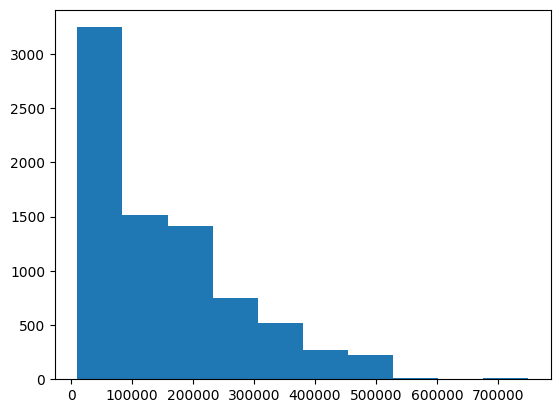

In [35]:
plt.hist(d1["Training"][d1["Training"].columns[0]])

In [36]:
d1["Training"][(d1["Target"]==0).to_numpy()]

,x1,x2,x5,x6,x7,x8,x9,x10,x11,x12,...,x14,x15,x16,x17,x18,x19,x20,x21,x22,x23
2083,310000.0,1,42,-2.0,-2.0,-2.0,-2.0,-2.0,-1.0,-606.0,...,19950.0,79227.0,20097.0,25594.0,45484.0,20033.0,79520.0,94.0,25910.0,10933.0
5147,20000.0,0,34,1.0,2.0,0.0,0.0,0.0,0.0,15095.0,...,12607.0,16430.0,19230.0,0.0,0.0,6000.0,5000.0,3000.0,0.0,0.0
675,20000.0,1,32,0.0,0.0,0.0,2.0,0.0,0.0,18539.0,...,21274.0,20109.0,19976.0,20143.0,1400.0,3300.0,0.0,1000.0,1000.0,1000.0
2545,130000.0,1,27,0.0,0.0,0.0,0.0,0.0,0.0,107599.0,...,112635.0,114472.0,117556.0,116090.0,4030.0,4600.0,4200.0,5000.0,5000.0,21932.0
3999,80000.0,1,26,0.0,0.0,0.0,0.0,0.0,0.0,78513.0,...,80131.0,75920.0,75421.0,73991.0,3000.0,5000.0,3500.0,8000.0,3000.0,3200.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6265,110000.0,1,46,0.0,0.0,0.0,0.0,0.0,0.0,45846.0,...,48325.0,0.0,49461.0,48438.0,2000.0,2000.0,2000.0,0.0,2000.0,2000.0
5734,280000.0,1,31,1.0,-2.0,-2.0,-2.0,-1.0,-1.0,0.0,...,0.0,0.0,5360.0,251.0,0.0,0.0,0.0,5360.0,251.0,5360.0
5191,50000.0,1,34,0.0,0.0,-1.0,-1.0,-1.0,-1.0,2435.0,...,197.0,2995.0,19515.0,0.0,0.0,197.0,2995.0,19515.0,0.0,3734.0
5390,10000.0,0,27,0.0,0.0,0.0,0.0,0.0,0.0,9457.0,...,7335.0,9025.0,7886.0,8382.0,1107.0,1310.0,2000.0,269.0,1000.0,1100.0


Here's a function that will compare the probability distributions of each feature, separated by the 2 populations:

In [37]:
import math
import scipy

def compare_features_binary(d,logscale=False):
    # Divide the data into separate dfs for the two categories
    
    df_0=d["Training"][(d["Target"]==0).to_numpy()]
    df_1=d["Training"][(d["Target"]==1).to_numpy()]
    
    print("Number of catogory 0:",df_0.shape[0])
    print("Number of catogory 1:",df_1.shape[0])
    
    # Make a grid of plots
    N_Features = d["Training"].shape[1]
    N_X= math.ceil(math.sqrt(N_Features))
    N_Y= math.floor(math.sqrt(N_Features))
    if N_X*N_Y<N_Features:
        N_Y+=1

    print("Found",N_Features,"features. Creating grid of",N_X,"by",N_Y)
    
    # Histogram Features
    plt.figure(figsize=(50,50))

    for i,column in enumerate(df_0.columns):
        # Fixed 2026-10: as numbers (recent scipy fails on pandas categorical columns, like x2)
        KS_test=scipy.stats.kstest(df_0[column].astype(float),df_1[column].astype(float)).statistic
        KS_test_str="{KS:.3f}".format(KS=KS_test)
        print(column,"KS Distribution Similarity Test:", KS_test_str)
        
        plt.subplot(N_X,N_Y,i+1)
        plt.title(KS_test_str)
        if logscale:
            plt.yscale("log")
        plt.hist(df_0[column],bins=100, histtype="step", color="red",label="0",density=1, stacked=True)
        plt.hist(df_1[column],bins=100, histtype="step", color="blue",label="1",density=1, stacked=True)
        plt.legend()
        plt.xlabel(column)
        
    plt.show()

Number of catogory 0: 3977
Number of catogory 1: 3986
Found 21 features. Creating grid of 5 by 5
x1 KS Distribution Similarity Test: 0.184
x2 KS Distribution Similarity Test: 0.051
x5 KS Distribution Similarity Test: 0.036
x6 KS Distribution Similarity Test: 0.366
x7 KS Distribution Similarity Test: 0.290
x8 KS Distribution Similarity Test: 0.256
x9 KS Distribution Similarity Test: 0.220
x10 KS Distribution Similarity Test: 0.187
x11 KS Distribution Similarity Test: 0.175
x12 KS Distribution Similarity Test: 0.046
x13 KS Distribution Similarity Test: 0.036
x14 KS Distribution Similarity Test: 0.027
x15 KS Distribution Similarity Test: 0.029
x16 KS Distribution Similarity Test: 0.028
x17 KS Distribution Similarity Test: 0.034
x18 KS Distribution Similarity Test: 0.150
x19 KS Distribution Similarity Test: 0.145
x20 KS Distribution Similarity Test: 0.145
x21 KS Distribution Similarity Test: 0.129
x22 KS Distribution Similarity Test: 0.119
x23 KS Distribution Similarity Test: 0.125


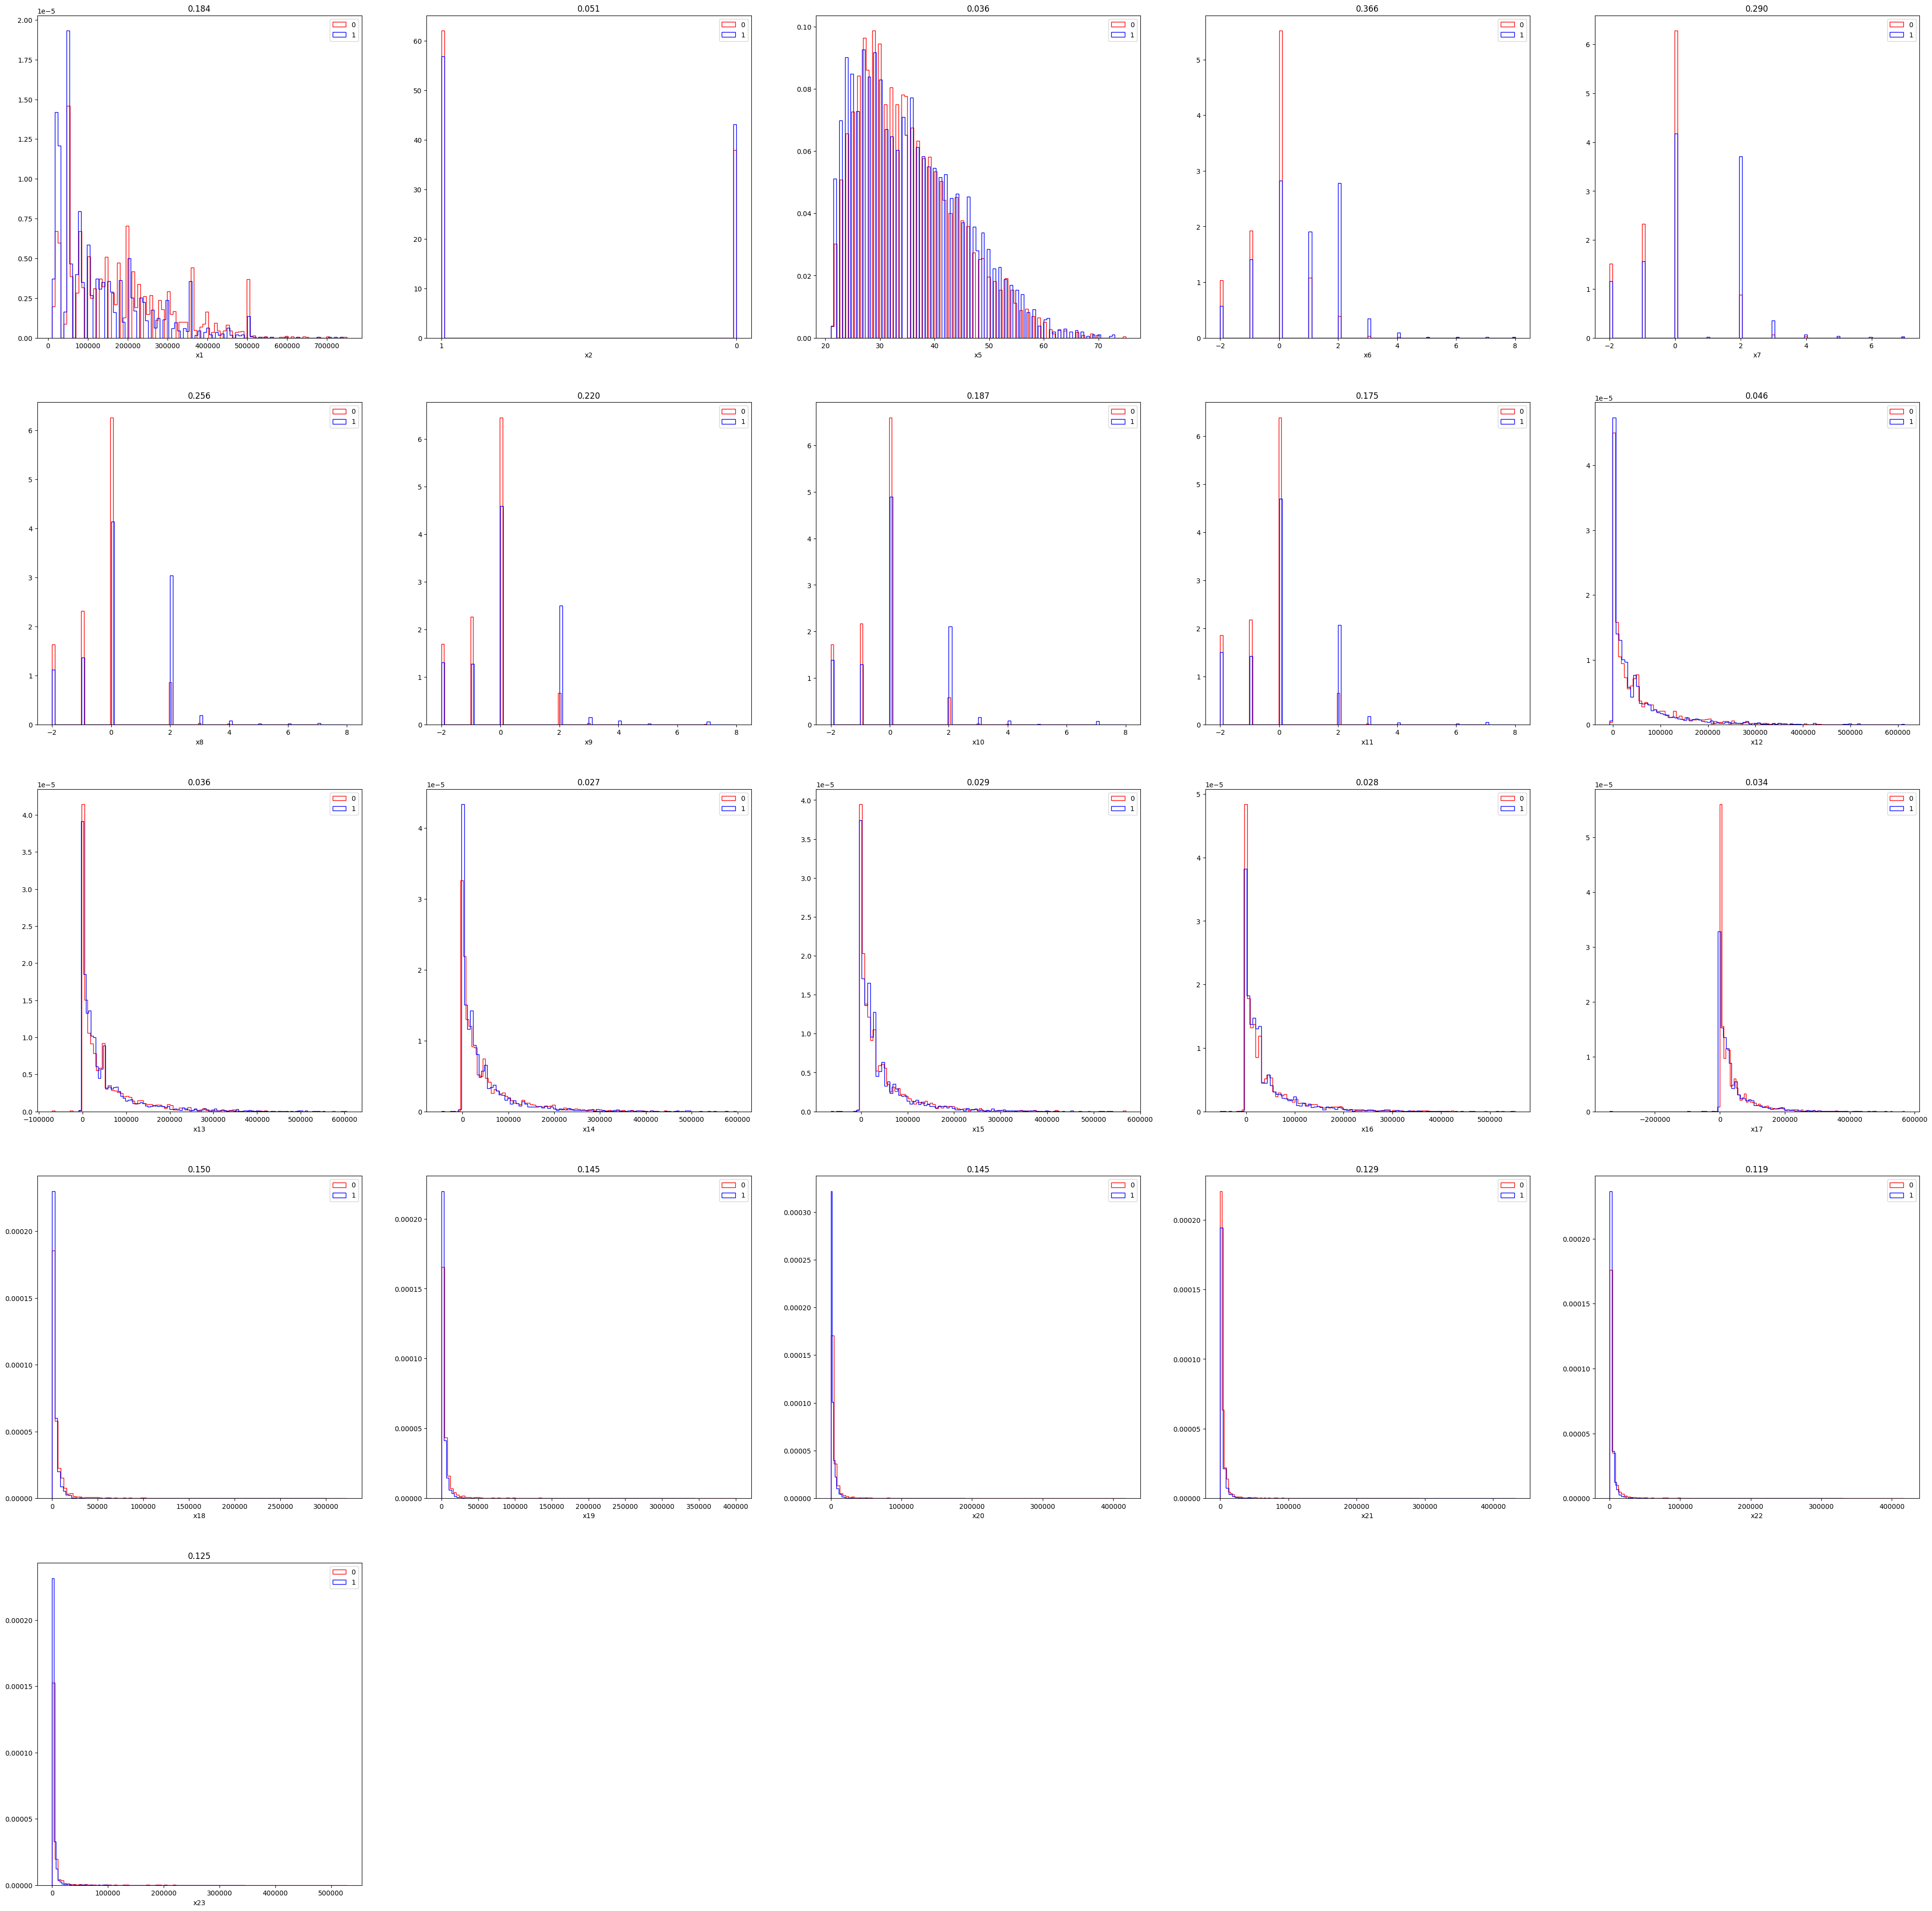

In [38]:
compare_features_binary(d1)

Histogram first: with two classes, overlaid histograms of every feature show you immediately
what's going on. The number above each panel is the **Kolmogorov–Smirnov (KS) statistic**: the
largest gap between the two classes' cumulative distributions. It is 0 for identical
distributions and 1 when they don't overlap at all, and it doesn't depend on the binning. It is a
number that confirms what your eye sees, and a quick score of each feature's usefulness on its own:
identical distributions mean "there's no separation power. It's not a good feature". Because it judges
each feature alone, it misses features that only help in combination (see the correlations below).

What the plots say: the strongest separation is in `x6`–`x9`, the most recent repayment statuses (KS
0.22–0.37). The credit limit and the payment amounts help somewhat (about 0.12–0.18). The six bill
amounts look alike for both classes (under 0.05). That is the kind of thing a client should hear from
you within fifteen minutes of handing you the data.

**Be curious.** Some bill-amount histograms show the same narrow spike in both classes. Is it a
fluctuation? It appears in several features, so it is not: it is a sub-population. It may not matter
for the task, "but you need to know that answer", because anyone you show this plot to will ask. Fine
binning (100 bins here) is what makes such structure, and quantized features, visible.

**Categorical or ordinal?** `x6`–`x11` take a few integer values, and the dataset treats them as
numbers, not categories. Is that right? Ask whether the order means something: could one threshold
on the feature separate the classes? If the integer labels could be shuffled without losing anything,
the feature is categorical; if not, it is ordinal. Months late are ordered, as is age. Treating them
as numbers is defensible, and so is one-hot encoding them, as below. It is a judgement call, and you
have to make it.

Number of catogory 0: 17271
Number of catogory 1: 17277
Found 54 features. Creating grid of 8 by 7
V1 KS Distribution Similarity Test: 0.235
V2 KS Distribution Similarity Test: 0.298
V3 KS Distribution Similarity Test: 0.097
V4 KS Distribution Similarity Test: 0.073
V5 KS Distribution Similarity Test: 0.170
V6 KS Distribution Similarity Test: 0.292
V7 KS Distribution Similarity Test: 0.090
V8 KS Distribution Similarity Test: 0.188
V9 KS Distribution Similarity Test: 0.043
V10 KS Distribution Similarity Test: 0.102
V11 KS Distribution Similarity Test: 0.186
V12 KS Distribution Similarity Test: 0.222
V13 KS Distribution Similarity Test: 0.260
V14 KS Distribution Similarity Test: 0.276
V15 KS Distribution Similarity Test: 0.286
V16 KS Distribution Similarity Test: 0.043
V17 KS Distribution Similarity Test: 0.102
V18 KS Distribution Similarity Test: 0.130
V19 KS Distribution Similarity Test: 0.189
V20 KS Distribution Similarity Test: 0.299
V21 KS Distribution Similarity Test: 0.206
V22 KS 

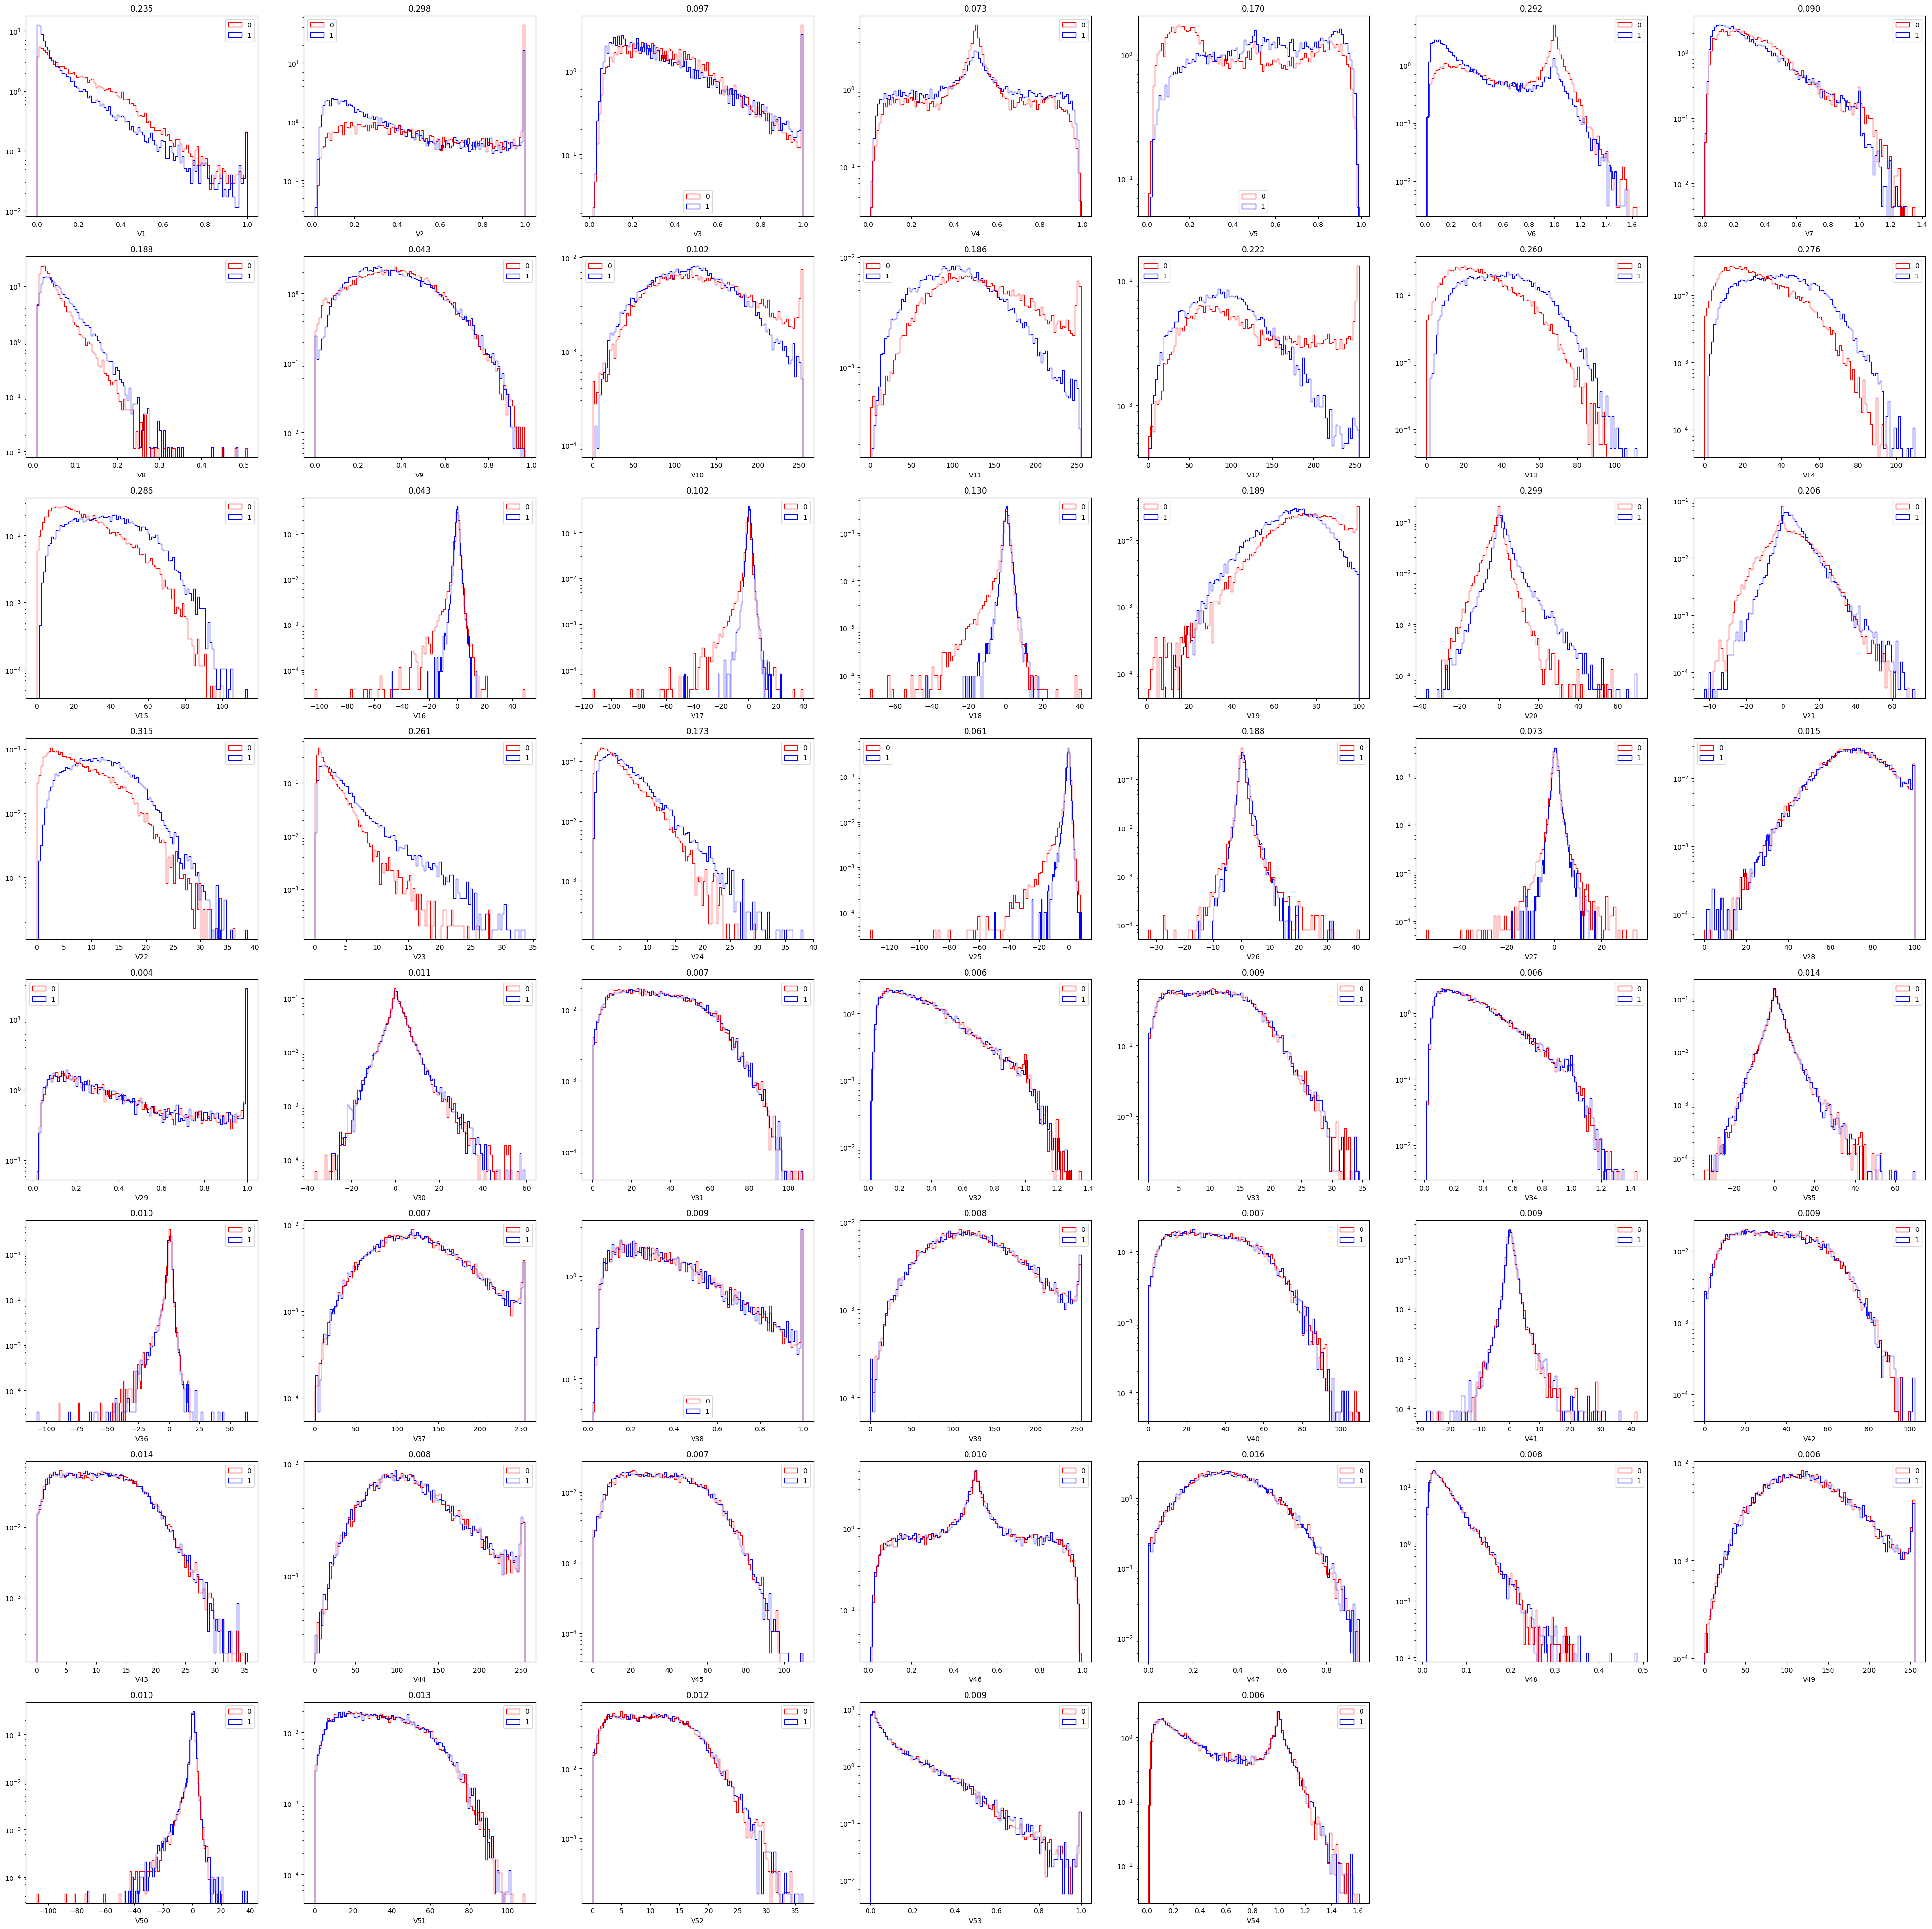

In [39]:
compare_features_binary(load_dataset("337_361274"),True)  # Fixed 2026-10: by name (was binary_classification[3])

## Correlations

Its often important to assess of features are correlated or not. For example, if 2 features are 100% correlated, then only one is needed for input to ML algorithms. The correlation information, coupled with the KS test results, can give us a sense of what features would be useful. 

Also, even if the distribution of features look the same for different populations, it is possible that the correlations are different between the populations, allowing discrimination between them. That means that looking at the correlations for different populations may give us additional insight into the dataset.

In [40]:
c_df = d1["Training"].corr()
c_df

,x1,x2,x5,x6,x7,x8,x9,x10,x11,x12,...,x14,x15,x16,x17,x18,x19,x20,x21,x22,x23
x1,1.000000,0.039029,0.149513,-0.284907,-0.324708,-0.316446,-0.296943,-0.278341,-0.258535,0.301183,...,0.296278,0.296822,0.300129,0.294138,0.210170,0.222058,0.214939,0.206587,0.227945,0.216992
x2,0.039029,1.000000,-0.098205,-0.044619,-0.055620,-0.060552,-0.048779,-0.046766,-0.035196,-0.018967,...,-0.006951,-0.002063,0.002440,-0.000767,0.002279,0.004498,-0.006159,0.008899,0.005467,-0.014645
x5,0.149513,-0.098205,1.000000,-0.036068,-0.041716,-0.043440,-0.030865,-0.034463,-0.037329,0.053037,...,0.056676,0.054305,0.055025,0.052088,0.032014,0.019607,0.018588,0.011756,0.018702,0.026865
x6,-0.284907,-0.044619,-0.036068,1.000000,0.679384,0.581331,0.542094,0.505396,0.467444,0.174717,...,0.182775,0.188796,0.191947,0.187664,-0.085626,-0.079734,-0.084254,-0.072435,-0.041690,-0.067914
x7,-0.324708,-0.055620,-0.041716,0.679384,1.000000,0.773745,0.650241,0.614772,0.576944,0.205327,...,0.210030,0.216376,0.216724,0.217918,-0.092902,-0.076767,-0.068093,-0.061942,-0.031161,-0.050081
x8,-0.316446,-0.060552,-0.043440,0.581331,0.773745,1.000000,0.782179,0.684648,0.641637,0.181102,...,0.210665,0.218093,0.217852,0.217721,-0.007805,-0.088325,-0.058773,-0.050243,-0.025736,-0.045723
x9,-0.296943,-0.048779,-0.030865,0.542094,0.650241,0.782179,1.000000,0.829194,0.728879,0.172159,...,0.223694,0.231051,0.230917,0.229914,-0.017887,-0.006091,-0.083558,-0.044293,-0.030436,-0.037307
x10,-0.278341,-0.046766,-0.034463,0.505396,0.614772,0.684648,0.829194,1.000000,0.829512,0.173290,...,0.217993,0.245320,0.245541,0.243222,-0.015503,-0.008526,-0.003992,-0.066466,-0.027960,-0.035328
x11,-0.258535,-0.035196,-0.037329,0.467444,0.576944,0.641637,0.728879,0.829512,1.000000,0.178161,...,0.218906,0.244848,0.268652,0.267993,-0.008334,-0.020224,-0.003844,0.007773,-0.041615,-0.029676
x12,0.301183,-0.018967,0.053037,0.174717,0.205327,0.181102,0.172159,0.173290,0.178161,1.000000,...,0.911035,0.873626,0.845783,0.826037,0.183261,0.134547,0.149021,0.191080,0.198915,0.188579


A correlation coefficient $\rho$ says: if one feature moves by one standard deviation, by how many
standard deviations does the other tend to move? Two features with $|\rho|$ near 1 carry the same
information, and many traditional algorithms do worse with redundant features. So look for highly
correlated pairs and consider keeping one of each. A colour map is the usual picture, but it fails
with many features, so below we flatten the matrix and sort it instead.

Another way to read $\rho$: take the examples one standard deviation above the mean in one feature. On
average, the other feature sits $\rho$ standard deviations above its own mean. With few features, a
**pair plot** (a scatter-plot matrix, as in the visualization lecture) shows the same by eye: every
feature against every other, with each feature's own histogram on the diagonal.

This is a big matrix of numbers, I don't want to look at it by eye. Lets see write some code to find the largest correlations:

In [45]:
# I prefer things in numpy tensors... less trouble later
# Need copy because otherwise read-only (assuming data is not copied)
c_matrix=c_df.to_numpy().copy()

Why `.copy()`? pandas can hand numpy a read-only view of its own storage, and the next cell writes
into the matrix.

Lets zero out the diagonal elements, since they are 1 and get in our way otherwise:

In [46]:
for i in range(c_matrix.shape[0]): c_matrix[i][i]=0.

Now lets flatten the matrix into a vector, but keep the info about what pairs of feature corresponds to each element. We can use an dictionary to keep the association. We'll use an `OrderedDict` since we will next sort: 

In [47]:
from collections import OrderedDict
corr_dict=OrderedDict()

for i in range(c_matrix.shape[0]):
    for j in range(c_matrix.shape[0]):
        corr_dict[(i,j)]=c_matrix[i][j]

Now sort:

In [48]:
corr_dict_sorted = OrderedDict(sorted(corr_dict.items(),
                                      key=lambda x: math.fabs(x[1])))

`sorted(..., key=...)` sorts the (pair, value) items by the absolute value of the correlation,
because a correlation of −1 is as strong as +1. (Since Python 3.7 a plain `dict` keeps insertion
order too, so `OrderedDict` is a safe habit rather than a necessity.)

Lets histogram the correlations to get a since of what is big and small:

(array([ 12.,  18., 151.,  68., 130.,   2.,   6.,  14.,   8.,  32.]),
 array([-0.32470844, -0.1965343 , -0.06836015,  0.05981399,  0.18798814,
         0.31616228,  0.44433643,  0.57251057,  0.70068471,  0.82885886,
         0.957033  ]),
 <BarContainer object of 10 artists>)

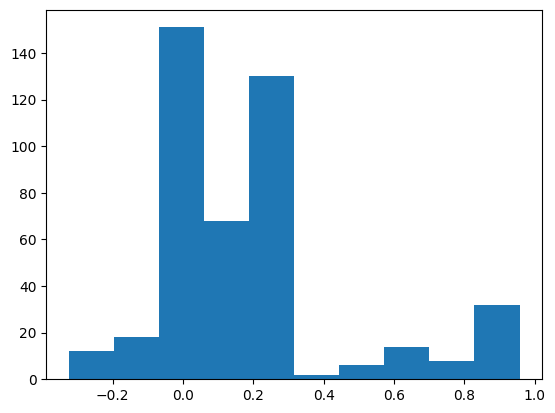

In [49]:
plt.hist(corr_dict_sorted.values())

This histogram summarizes the whole matrix at once: most pairs between 0 and 0.3, a group near 0.9
(almost the same feature twice), and a few negative ones, down to about −0.3. Every pair is counted twice. It answers "is this data mostly new
information, mostly redundant, or a mixture?" before you look at any single pair.

Lets look at the top correlations:

In [50]:
list(zip(list(corr_dict_sorted.keys())[-1:-25:-1],list(corr_dict_sorted.values())[-1:-25:-1]))

[((10, 9), np.float64(0.9570330035266036)),
 ((9, 10), np.float64(0.9570330035266036)),
 ((14, 13), np.float64(0.9533876637026473)),
 ((13, 14), np.float64(0.9533876637026473)),
 ((13, 12), np.float64(0.9506111502999005)),
 ((12, 13), np.float64(0.9506111502999005)),
 ((12, 11), np.float64(0.9501370303346989)),
 ((11, 12), np.float64(0.9501370303346989)),
 ((11, 10), np.float64(0.9450097017865611)),
 ((10, 11), np.float64(0.9450097017865611)),
 ((13, 11), np.float64(0.9150211913951499)),
 ((11, 13), np.float64(0.9150211913951499)),
 ((14, 12), np.float64(0.9144297515618338)),
 ((12, 14), np.float64(0.9144297515618338)),
 ((11, 9), np.float64(0.9110353593896339)),
 ((9, 11), np.float64(0.9110353593896339)),
 ((12, 10), np.float64(0.910533471699806)),
 ((10, 12), np.float64(0.910533471699806)),
 ((14, 11), np.float64(0.8814258127122916)),
 ((11, 14), np.float64(0.8814258127122916)),
 ((13, 10), np.float64(0.8788280314158656)),
 ((10, 13), np.float64(0.8788280314158656)),
 ((12, 9), np.fl

Reading the list: every pair appears twice, because the matrix is symmetric. Columns 9–14 are
`x12`–`x17`, the six monthly bill amounts, and the top correlations (0.88–0.96) are between
neighbouring months. Of course they correlate: they are slightly different versions of each other,
so you probably don't need all of them.

Choosing a smaller set of inputs is **feature selection**. Of a group of highly correlated features,
keep one; an automatic feature-selection algorithm does the same, and which one it keeps can change
from run to run "just because of statistical fluctuations", since they carry the same information.
Nearly uncorrelated features either carry different information or are noise. Datasets in this
benchmark go up to about 1,800 features, and there a study of a smaller subset is worth doing: it often
performs better. It is also a finding worth reporting: telling whoever gave you the data that a block
of their features is "all the same stuff" is useful.

Now lets do this separating by population:

In [51]:
c_df_0 = d1["Training"][(d1["Target"]==0).to_numpy()].corr()
c_df_1 = d1["Training"][(d1["Target"]==1).to_numpy()].corr()

We'll wrap the steps above into a function so we don't have to copy and paste code:

In [97]:
def matrix_to_dict(c_matrix):
    c_matrix_0=c_df_0.to_numpy()
    corr_dict = OrderedDict()
    for i in range(c_matrix.shape[0]): c_matrix[i][i]=0.

    for i in range(c_matrix.shape[0]):
        for j in range(c_matrix.shape[0]):
            corr_dict[(i,j)]=c_matrix[i][j]

        
    corr_dict_sorted = OrderedDict(sorted(corr_dict.items(),
                                      key=lambda x: math.fabs(x[1])))
    return corr_dict_sorted       

In [98]:
corr_dict_sorted_0 = matrix_to_dict(c_df_0.to_numpy().copy())
corr_dict_sorted_1 = matrix_to_dict(c_df_1.to_numpy().copy())

Lets check of the top correlations are the same:

In [99]:
list(zip(zip(list(corr_dict_sorted_0.keys())[-1:-25:-1],list(corr_dict_sorted_0.values())[-1:-25:-1]),
         zip(list(corr_dict_sorted_1.keys())[-1:-25:-1],list(corr_dict_sorted_1.values())[-1:-25:-1])))

[(((14, 13), np.float64(0.9499147315177627)),
  ((10, 9), np.float64(0.9738914942451167))),
 (((13, 14), np.float64(0.9499147315177627)),
  ((9, 10), np.float64(0.9738914942451167))),
 (((13, 12), np.float64(0.9402603085150995)),
  ((11, 10), np.float64(0.9629475051217274))),
 (((12, 13), np.float64(0.9402603085150995)),
  ((10, 11), np.float64(0.9629475051217274))),
 (((10, 9), np.float64(0.9394324952085749)),
  ((12, 11), np.float64(0.9617823737124945))),
 (((9, 10), np.float64(0.9394324952085749)),
  ((11, 12), np.float64(0.9617823737124945))),
 (((12, 11), np.float64(0.9377481456048278)),
  ((13, 12), np.float64(0.9604117680976004))),
 (((11, 12), np.float64(0.9377481456048278)),
  ((12, 13), np.float64(0.9604117680976004))),
 (((11, 10), np.float64(0.9259976380315671)),
  ((14, 13), np.float64(0.956934161465363))),
 (((10, 11), np.float64(0.9259976380315671)),
  ((13, 14), np.float64(0.956934161465363))),
 (((14, 12), np.float64(0.9031568731945958)),
  ((12, 10), np.float64(0.9352

ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/zmq/eventloop/zmqstream.py", line 550, in _run_callback
    f = callback(*args, **kwargs)
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/ipykernel/iostream.py", line 105, in _handle_subscription
    event_type = frame[0]
                 ~~~~~^^^
IndexError: index out of range
ERROR:tornado.general:Uncaught exception in zmqstream callback
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/zmq/eventloop/zmqstream.py", line 600, in _handle_events
    self._handle_recv()
    ~~~~~~~~~~~~~~~~~^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/zmq/eventloop/zmqstream.py", line 629, in _handle_recv
    self._run_callback(callback, msg)
    ~~~~~~~~~~~~~~~~~~^

Why separate the populations? Two classes can have identical histograms for every feature and
still differ in how the features move together. (For example, high blood sugar may mean something
different in the old and the young.) Fisher's discriminant uses exactly those differences. A cleaner
comparison than reading two lists is to subtract the two correlation matrices.

It doesn't appear that there is correlations differences between the population.

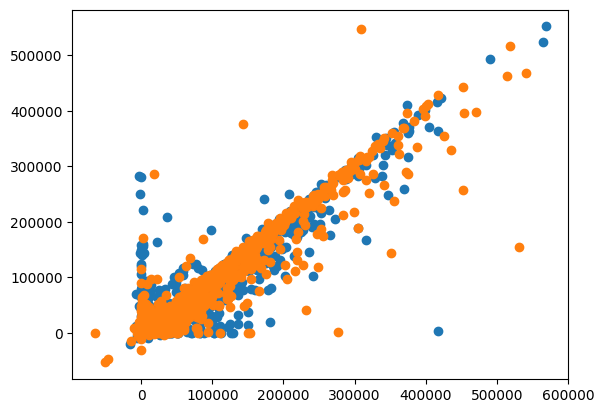

In [56]:
df_0 = d1["Training"][(d1["Target"]==0).to_numpy()]
df_1 = d1["Training"][(d1["Target"]==1).to_numpy()]

plt.scatter(df_0.iloc[:,12],df_0.iloc[:,13])
plt.scatter(df_1.iloc[:,12],df_1.iloc[:,13])

The scatter plot is columns 12 and 13, `x15` against `x16`: two neighbouring months' bills, hence
the diagonal line.

## Multiclass

Quick side... if we wanted to look into multiclass classification dataset, we would do the same things separately for each class (aka population). For regression, we can create populations by binning in the target value, for example low, medium, and high values.

Here's an example modification, we allows me to specify the populations more generically in a dictionary:

In [57]:
def compare_features_multiclass(d,selections,logscale=False):
    # Divide the data into separate dfs for the two categories
    
    dfs = dict()
    for name,selection in selections.items():
        dfs[name] = d["Training"][eval(selection).to_numpy()]
        print("Number of catogory 0:",dfs[name])
        
    # Make a grid of plots
    N_Features = d["Training"].shape[1]
    N_X= math.ceil(math.sqrt(N_Features))
    N_Y= math.floor(math.sqrt(N_Features))
    if N_X*N_Y<N_Features:
        N_Y+=1

    print("Found",N_Features,"features. Creating grid of",N_X,"by",N_Y)
    
    # Histogram Features
    plt.figure(figsize=(50,50))

    for i,column in enumerate(d["Training"].columns):
        #KS_test=scipy.stats.kstest(df_0[column],df_1[column]).statistic
        #print(column,"KS Distribution Similarity Test:", KS_test)
        
        plt.subplot(N_X,N_Y,i+1)
        #plt.title(str(KS_test))
        if logscale:
            plt.yscale("log")
        for name,selection in selections.items():
            plt.hist(dfs[name][column],bins=100, histtype="step",label=name,density=1, stacked=True)
        plt.legend()
        plt.xlabel(column)
        
    plt.show()

In [58]:
d2= load_dataset("336_361076")  # Fixed 2026-10: by name (was multi_classification[10])

In [59]:
np.unique(d2["Target"])

array([3, 4, 5, 6, 7, 8, 9], dtype=uint8)

Number of catogory 0:       Precinct Sector  Occurred_hour  Occurred_min
26765        0      5              0             0
46157        4      7              4             4
22874        1      0              0             0
30550        3      4              0             0
4143         2     14              0             0
...        ...    ...            ...           ...
27890        4     12              0             0
48033        4     12              0             0
26557        4     12             19            19
14541        4      9             22            22
19118        3     16             22            22

[1885 rows x 4 columns]
Number of catogory 0:       Precinct Sector  Occurred_hour  Occurred_min
8742         4      7              0             1
5953         1      6             22            22
29470        4      9              0             1
4022         1      8             20            20
11540        1      0              0             1
9373         

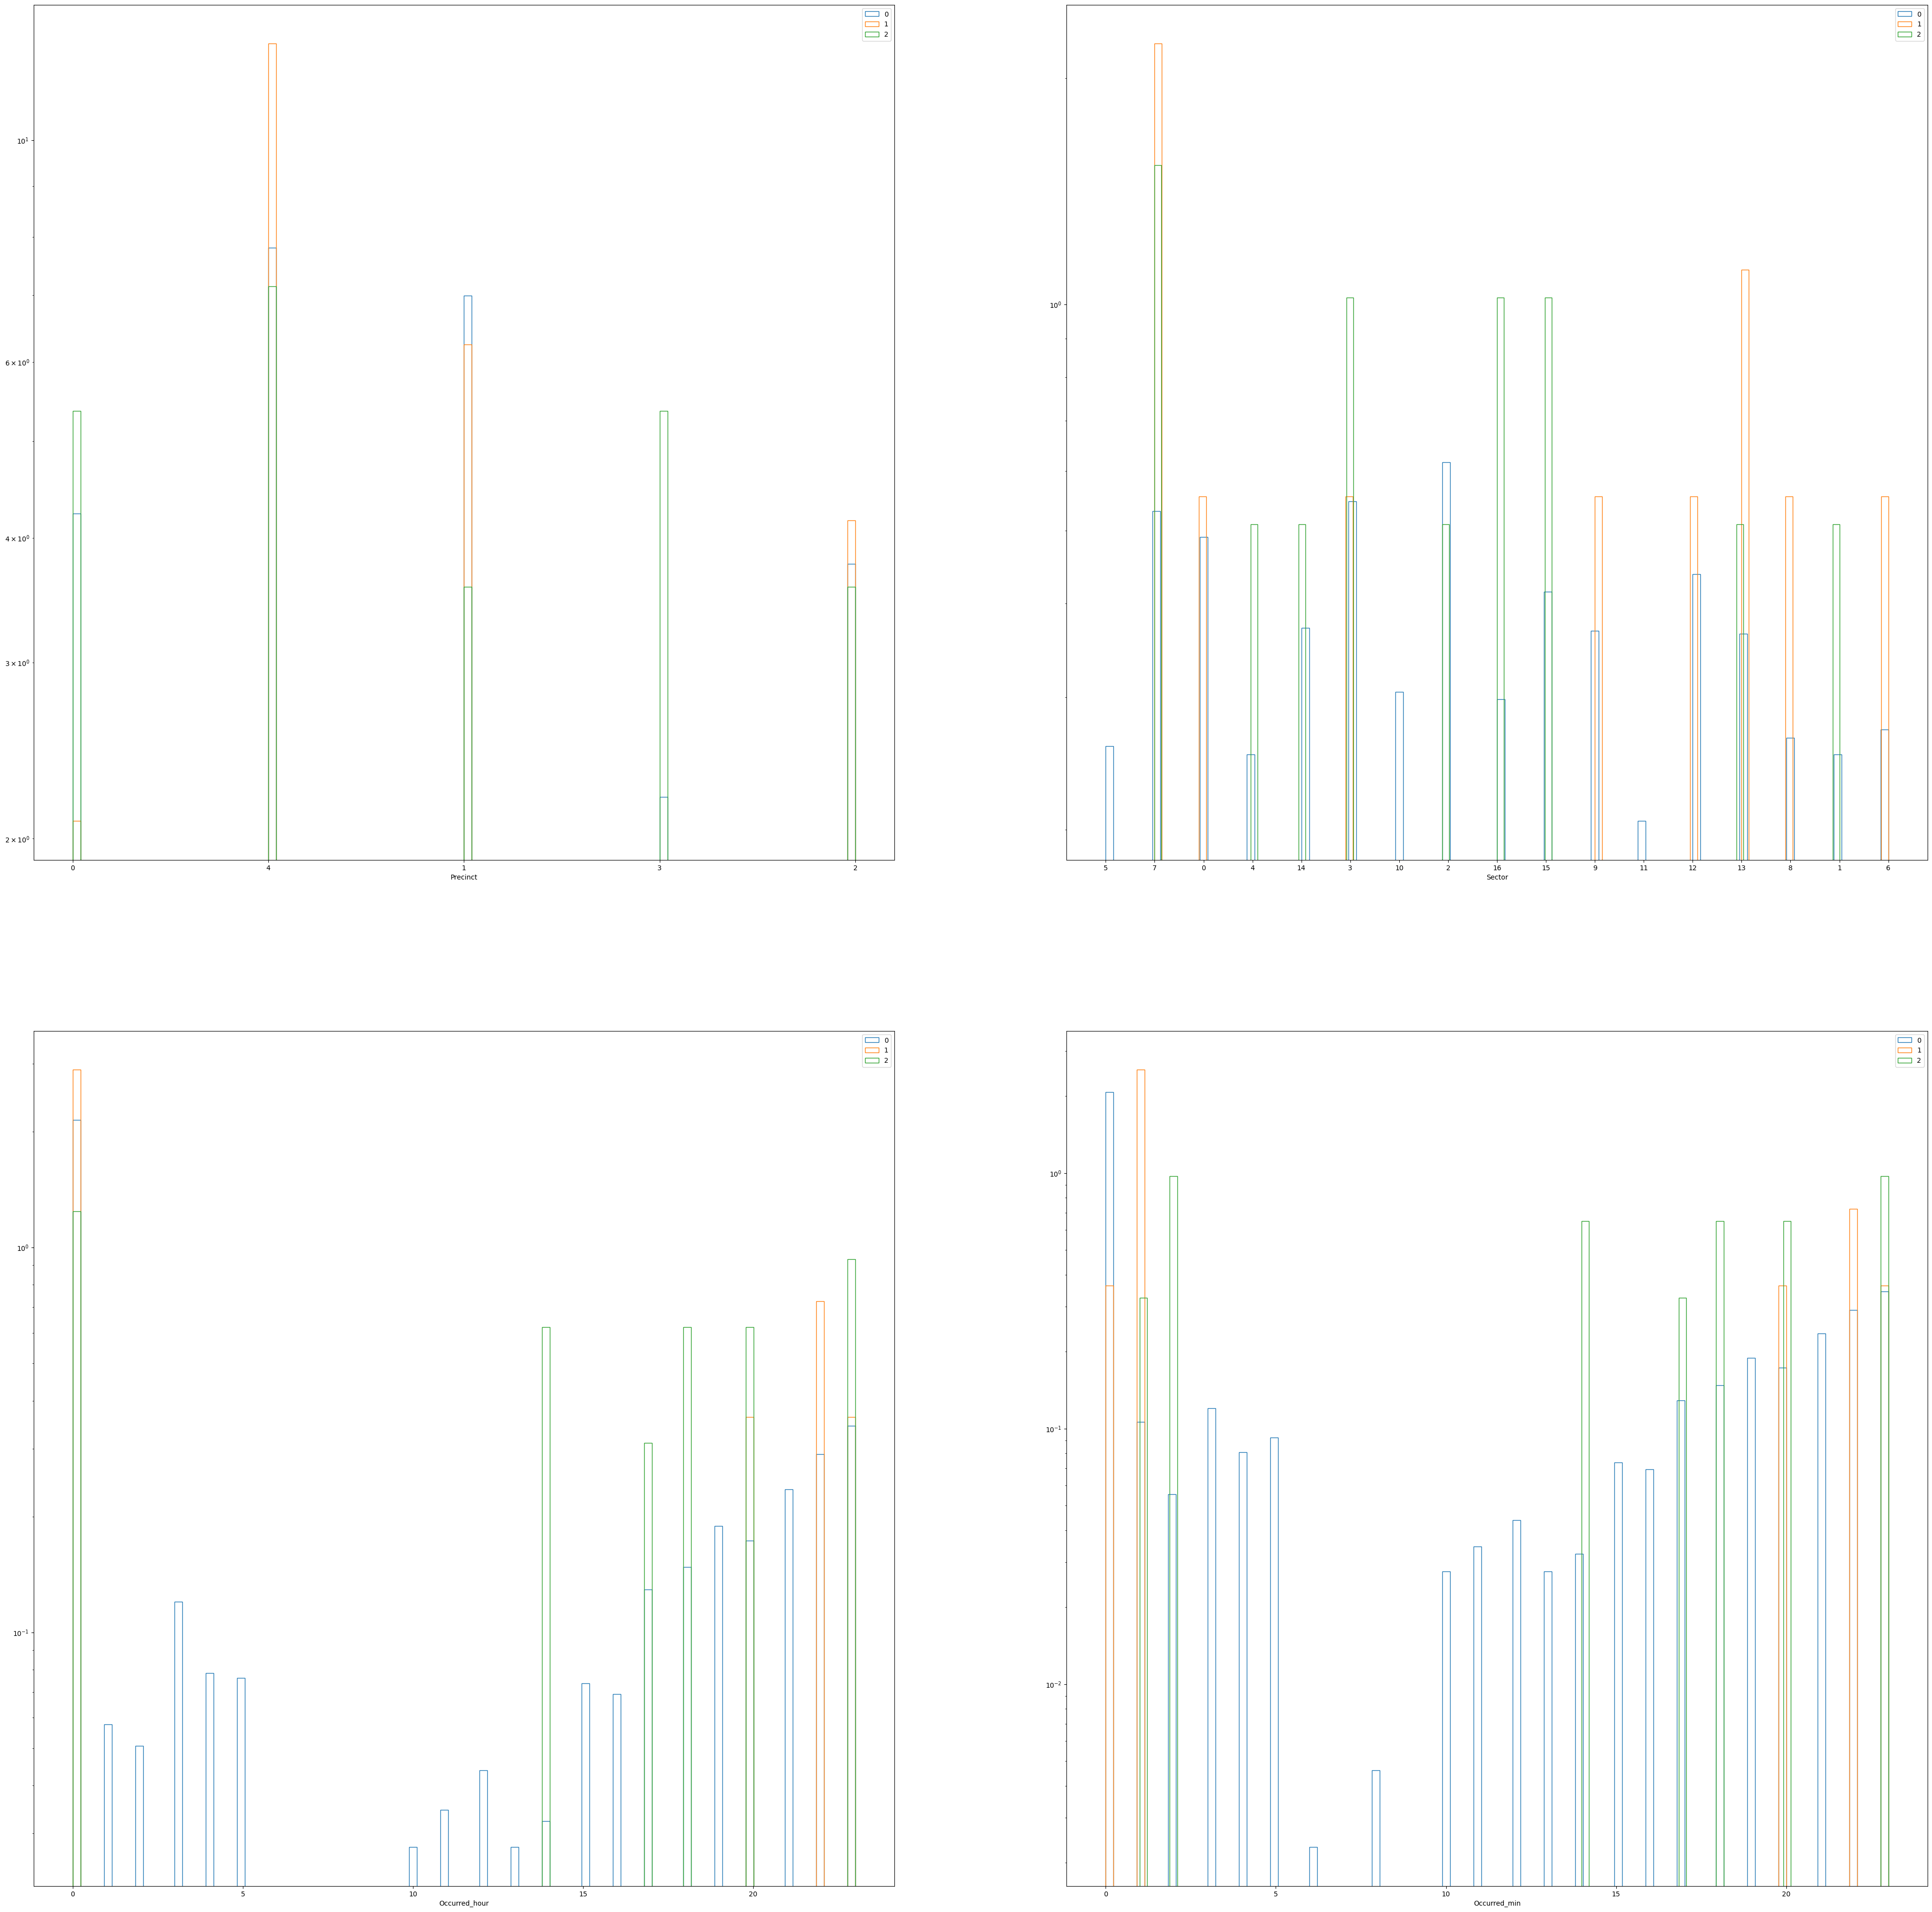

In [60]:
# Fixed 2026-10: by name (was multi_classification[1])
compare_features_multiclass(load_dataset("335_361289"),
                        {"0":"d['Target']==0",
                        "1":"d['Target']==1",
                        "2":"d['Target']==2"
                        },
                        True)

A caution about the plot above. As noted earlier, this "multiclass" dataset is really a regression
task: `335_361289` predicts a reported time, and the selections 0, 1 and 2 pick out only 1,885, 12
and 14 of its 31,218 rows. For a regression target, bin the target instead and compare the bins.
The function itself works for any number of classes.

**Your project.** The Kaggle project checklist asks for the same things this lecture does: class
balance (**class imbalance** means many more examples of one class than another; check it first,
because it changes what a good accuracy is), a table describing the features, outliers, and then the preparation below: one-hot encode
the categorical features, and bring the numerical ones to about the same range. With hundreds of
features, describe groups ("about 200 features that look like this") rather than each one.

## Categorical Variables

In [61]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder

In [62]:
d1["Training"]["x2"]

7249     1
8814     0
2083     1
7735     0
10646    1
        ..
11964    1
5191     1
5390     0
860      1
7270     1
Name: x2, Length: 7963, dtype: category
Categories (2, str): ['0' < '1']

In [63]:
d1["Training"]

,x1,x2,x5,x6,x7,x8,x9,x10,x11,x12,...,x14,x15,x16,x17,x18,x19,x20,x21,x22,x23
7249,30000.0,1,22,0.0,0.0,0.0,2.0,0.0,0.0,27444.0,...,29886.0,28392.0,22612.0,22750.0,2000.0,1800.0,0.0,1000.0,1000.0,0.0
8814,50000.0,0,41,4.0,3.0,2.0,0.0,0.0,-1.0,52955.0,...,50307.0,27707.0,28479.0,28979.0,0.0,0.0,0.0,974.0,31100.0,1200.0
2083,310000.0,1,42,-2.0,-2.0,-2.0,-2.0,-2.0,-1.0,-606.0,...,19950.0,79227.0,20097.0,25594.0,45484.0,20033.0,79520.0,94.0,25910.0,10933.0
7735,150000.0,0,56,2.0,0.0,0.0,0.0,0.0,0.0,116928.0,...,43045.0,40813.0,42164.0,43465.0,5006.0,3000.0,1452.0,5000.0,5000.0,2000.0
10646,120000.0,1,33,0.0,0.0,0.0,-1.0,-1.0,0.0,35563.0,...,19747.0,1201.0,2333.0,2250.0,1426.0,6400.0,1500.0,2700.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11964,50000.0,1,50,1.0,-2.0,-2.0,-2.0,-2.0,-2.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5191,50000.0,1,34,0.0,0.0,-1.0,-1.0,-1.0,-1.0,2435.0,...,197.0,2995.0,19515.0,0.0,0.0,197.0,2995.0,19515.0,0.0,3734.0
5390,10000.0,0,27,0.0,0.0,0.0,0.0,0.0,0.0,9457.0,...,7335.0,9025.0,7886.0,8382.0,1107.0,1310.0,2000.0,269.0,1000.0,1100.0
860,50000.0,1,23,0.0,0.0,0.0,0.0,-1.0,0.0,48482.0,...,11151.0,-2897.0,48211.0,48154.0,2500.0,3002.0,1500.0,52000.0,1900.0,1800.0


In [64]:
cat_varnames=["x2","x5","x6","x7","x8","x9","x10","x11"]

In [65]:
[len(d1["Training"][x].unique()) for x in cat_varnames]

[2, 53, 11, 10, 11, 11, 10, 10]

A quick test of "is this categorical?": count the distinct values. A feature with few values compared
with the number of rows is at least quantized. Here: 2, 53, 11, 10, 11, 11, 10, 10, against 7,963 rows.
Whether it is *categorical* is still the ordinal question from above; `x5`, with 53 values, is age, a
measurement.

In [66]:
d1["Training"][cat_varnames]

,x2,x5,x6,x7,x8,x9,x10,x11
7249,1,22,0.0,0.0,0.0,2.0,0.0,0.0
8814,0,41,4.0,3.0,2.0,0.0,0.0,-1.0
2083,1,42,-2.0,-2.0,-2.0,-2.0,-2.0,-1.0
7735,0,56,2.0,0.0,0.0,0.0,0.0,0.0
10646,1,33,0.0,0.0,0.0,-1.0,-1.0,0.0
...,...,...,...,...,...,...,...,...
11964,1,50,1.0,-2.0,-2.0,-2.0,-2.0,-2.0
5191,1,34,0.0,0.0,-1.0,-1.0,-1.0,-1.0
5390,0,27,0.0,0.0,0.0,0.0,0.0,0.0
860,1,23,0.0,0.0,0.0,0.0,-1.0,0.0


In [67]:
encoder=OneHotEncoder()
encoder.fit(d1["Training"][cat_varnames])

,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a :class:`scipy.sparse.csr_matrix`,i.e. a sparse matrix in ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",True
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide `.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'error'
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide `.",None
,"max_catego

In [68]:
encoded = pd.DataFrame(encoder.transform(d1["Training"][cat_varnames]).toarray())

In [69]:
encoded

,0,1,2,3,4,5,6,7,8,9,...,108,109,110,111,112,113,114,115,116,117
0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7958,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7959,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7960,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7961,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Why one-hot?** Category labels have no order, so giving a model the label as a number lets it draw
boundaries that mean nothing. A `LabelEncoder` maps labels (strings, say) to integers; a
`OneHotEncoder` turns each label into its own 0/1 column. (Current scikit-learn's `OneHotEncoder`
takes strings directly; `LabelEncoder` is meant for targets.) Here the 8 categorical columns become 118:
2 + 53 + 11 + 10 + 11 + 11 + 10 + 10. Age alone (`x5`) becomes 53 columns, although age is a
measurement, and binning it into a few ranges would be another reasonable choice.

**`fit`, then `transform`.** `fit` learns the mapping; `transform` applies what was learned. The
mapping lives in the encoder instance, and a different sample could produce a different
assignment, so keep the instance and reuse it (save it with `pickle`, as in Chapter 4) for any new
data. Most encoders and scalers can also run backwards (`inverse_transform`), which is another reason
to keep the instance: without it you can't decode your results. `fit_transform` does both steps at once.

**When to bin a measurement.** A linear model can only put one cut on a single feature. If age matters
in three regimes that behave differently (young, middle-aged, old), one cut can't capture that, and
three categories can: "encoding age as just a number in a linear algorithm is not as good as encoding
it as young, middle-aged and old". A tree can make several cuts on its own. The honest answer is to
"try it both ways and see".

## Normalizing Data


In [70]:
d1["Training"].info()

<class 'pandas.DataFrame'>
Index: 7963 entries, 7249 to 7270
Data columns (total 21 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   x1      7963 non-null   float64 
 1   x2      7963 non-null   category
 2   x5      7963 non-null   uint8   
 3   x6      7963 non-null   float64 
 4   x7      7963 non-null   float64 
 5   x8      7963 non-null   float64 
 6   x9      7963 non-null   float64 
 7   x10     7963 non-null   float64 
 8   x11     7963 non-null   float64 
 9   x12     7963 non-null   float64 
 10  x13     7963 non-null   float64 
 11  x14     7963 non-null   float64 
 12  x15     7963 non-null   float64 
 13  x16     7963 non-null   float64 
 14  x17     7963 non-null   float64 
 15  x18     7963 non-null   float64 
 16  x19     7963 non-null   float64 
 17  x20     7963 non-null   float64 
 18  x21     7963 non-null   float64 
 19  x22     7963 non-null   float64 
 20  x23     7963 non-null   float64 
dtypes: category(1), float64(19)

In [71]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

Why scale? Some features here run into the hundreds of thousands (the credit limit, the bills), and
others from −2 to 8. Many algorithms optimize something, and "if they're not about the same range, the
optimization doesn't work so well".

Two common scalers: `StandardScaler` subtracts each feature's mean and divides by its standard
deviation; `MinMaxScaler` maps each feature to $[0, 1]$, subtracting the minimum and dividing by
(max − min). Each feature is scaled separately. Fit the scaler **once**, on the training sample, and
apply that same instance to everything else, so that all samples share one scale. Which scaler is
better for a given feature is often not obvious: try both and keep the one that does better on the
validation sample. (This notebook fits the encoder and the scaler on all the rows before splitting
them below, which **leaks** a little information from the test rows into the training: information
from data meant for testing reaches the model.)

Keep a copy of the original DataFrame.

In [72]:
import copy
d1["Training_0"]=copy.deepcopy(d1["Training"])

In [73]:
d1["Training"] = d1["Training"].drop(columns=cat_varnames)   # Fixed 2026-10: assign the result (drop returns a new DataFrame)
d1["Training"]

,x1,x12,x13,x14,x15,x16,x17,x18,x19,x20,x21,x22,x23
7249,30000.0,27444.0,29000.0,29886.0,28392.0,22612.0,22750.0,2000.0,1800.0,0.0,1000.0,1000.0,0.0
8814,50000.0,52955.0,51847.0,50307.0,27707.0,28479.0,28979.0,0.0,0.0,0.0,974.0,31100.0,1200.0
2083,310000.0,-606.0,44878.0,19950.0,79227.0,20097.0,25594.0,45484.0,20033.0,79520.0,94.0,25910.0,10933.0
7735,150000.0,116928.0,87215.0,43045.0,40813.0,42164.0,43465.0,5006.0,3000.0,1452.0,5000.0,5000.0,2000.0
10646,120000.0,35563.0,25614.0,19747.0,1201.0,2333.0,2250.0,1426.0,6400.0,1500.0,2700.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11964,50000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5191,50000.0,2435.0,0.0,197.0,2995.0,19515.0,0.0,0.0,197.0,2995.0,19515.0,0.0,3734.0
5390,10000.0,9457.0,9554.0,7335.0,9025.0,7886.0,8382.0,1107.0,1310.0,2000.0,269.0,1000.0,1100.0
860,50000.0,48482.0,47226.0,11151.0,-2897.0,48211.0,48154.0,2500.0,3002.0,1500.0,52000.0,1900.0,1800.0


**Corrected 2026-10.** The cell above used to read `d1["Training"].drop(columns=cat_varnames)` on its
own. `drop` does not change the DataFrame: it **returns a new one**, and that result was thrown
away, so the categorical columns stayed in, were min-max scaled with the rest, and then sat beside
their own one-hot columns. The intent was to drop the categorical columns, scale the remaining
numerical ones, and merge the one-hot columns back in. Assigning the result does that; the second
line still displays the table. The outputs below are from re-running the notebook with the fix: 13
scaled columns instead of 21, and 131 columns in total instead of 139.

In [74]:
scaler_minmax = MinMaxScaler()
d1["Training"]=pd.DataFrame(scaler_minmax.fit_transform(d1["Training"]))

In [75]:
d1["Training"]

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,0.027027,0.055603,0.146180,0.118117,0.147523,0.125050,0.398961,0.006192,0.004489,0.000000,0.002314,0.002392,0.000000
1,0.054054,0.096687,0.179992,0.149849,0.146443,0.134752,0.405820,0.000000,0.000000,0.000000,0.002254,0.074404,0.002270
2,0.405405,0.010429,0.169678,0.102677,0.227679,0.120891,0.402093,0.140811,0.049957,0.190427,0.000218,0.061987,0.020680
3,0.189189,0.199713,0.232333,0.138564,0.167108,0.157383,0.421769,0.015498,0.007481,0.003477,0.011571,0.011962,0.003783
4,0.148649,0.068678,0.141169,0.102362,0.104648,0.091515,0.376390,0.004415,0.015960,0.003592,0.006248,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7958,0.054054,0.011405,0.103263,0.071677,0.102754,0.087657,0.373913,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
7959,0.054054,0.015327,0.103263,0.071983,0.107477,0.119929,0.373913,0.000000,0.000491,0.007172,0.045160,0.000000,0.007063
7960,0.000000,0.026635,0.117402,0.083075,0.116985,0.100698,0.383142,0.003427,0.003267,0.004789,0.000622,0.002392,0.002081
7961,0.054054,0.089483,0.173153,0.089004,0.098187,0.167383,0.426932,0.007740,0.007486,0.003592,0.120334,0.004546,0.003405


Number of catogory 0: 3977
Number of catogory 1: 3986
Found 13 features. Creating grid of 4 by 4
0 KS Distribution Similarity Test: 0.184
1 KS Distribution Similarity Test: 0.046
2 KS Distribution Similarity Test: 0.036
3 KS Distribution Similarity Test: 0.027
4 KS Distribution Similarity Test: 0.029
5 KS Distribution Similarity Test: 0.028
6 KS Distribution Similarity Test: 0.034
7 KS Distribution Similarity Test: 0.150
8 KS Distribution Similarity Test: 0.145
9 KS Distribution Similarity Test: 0.145
10 KS Distribution Similarity Test: 0.129
11 KS Distribution Similarity Test: 0.119
12 KS Distribution Similarity Test: 0.125


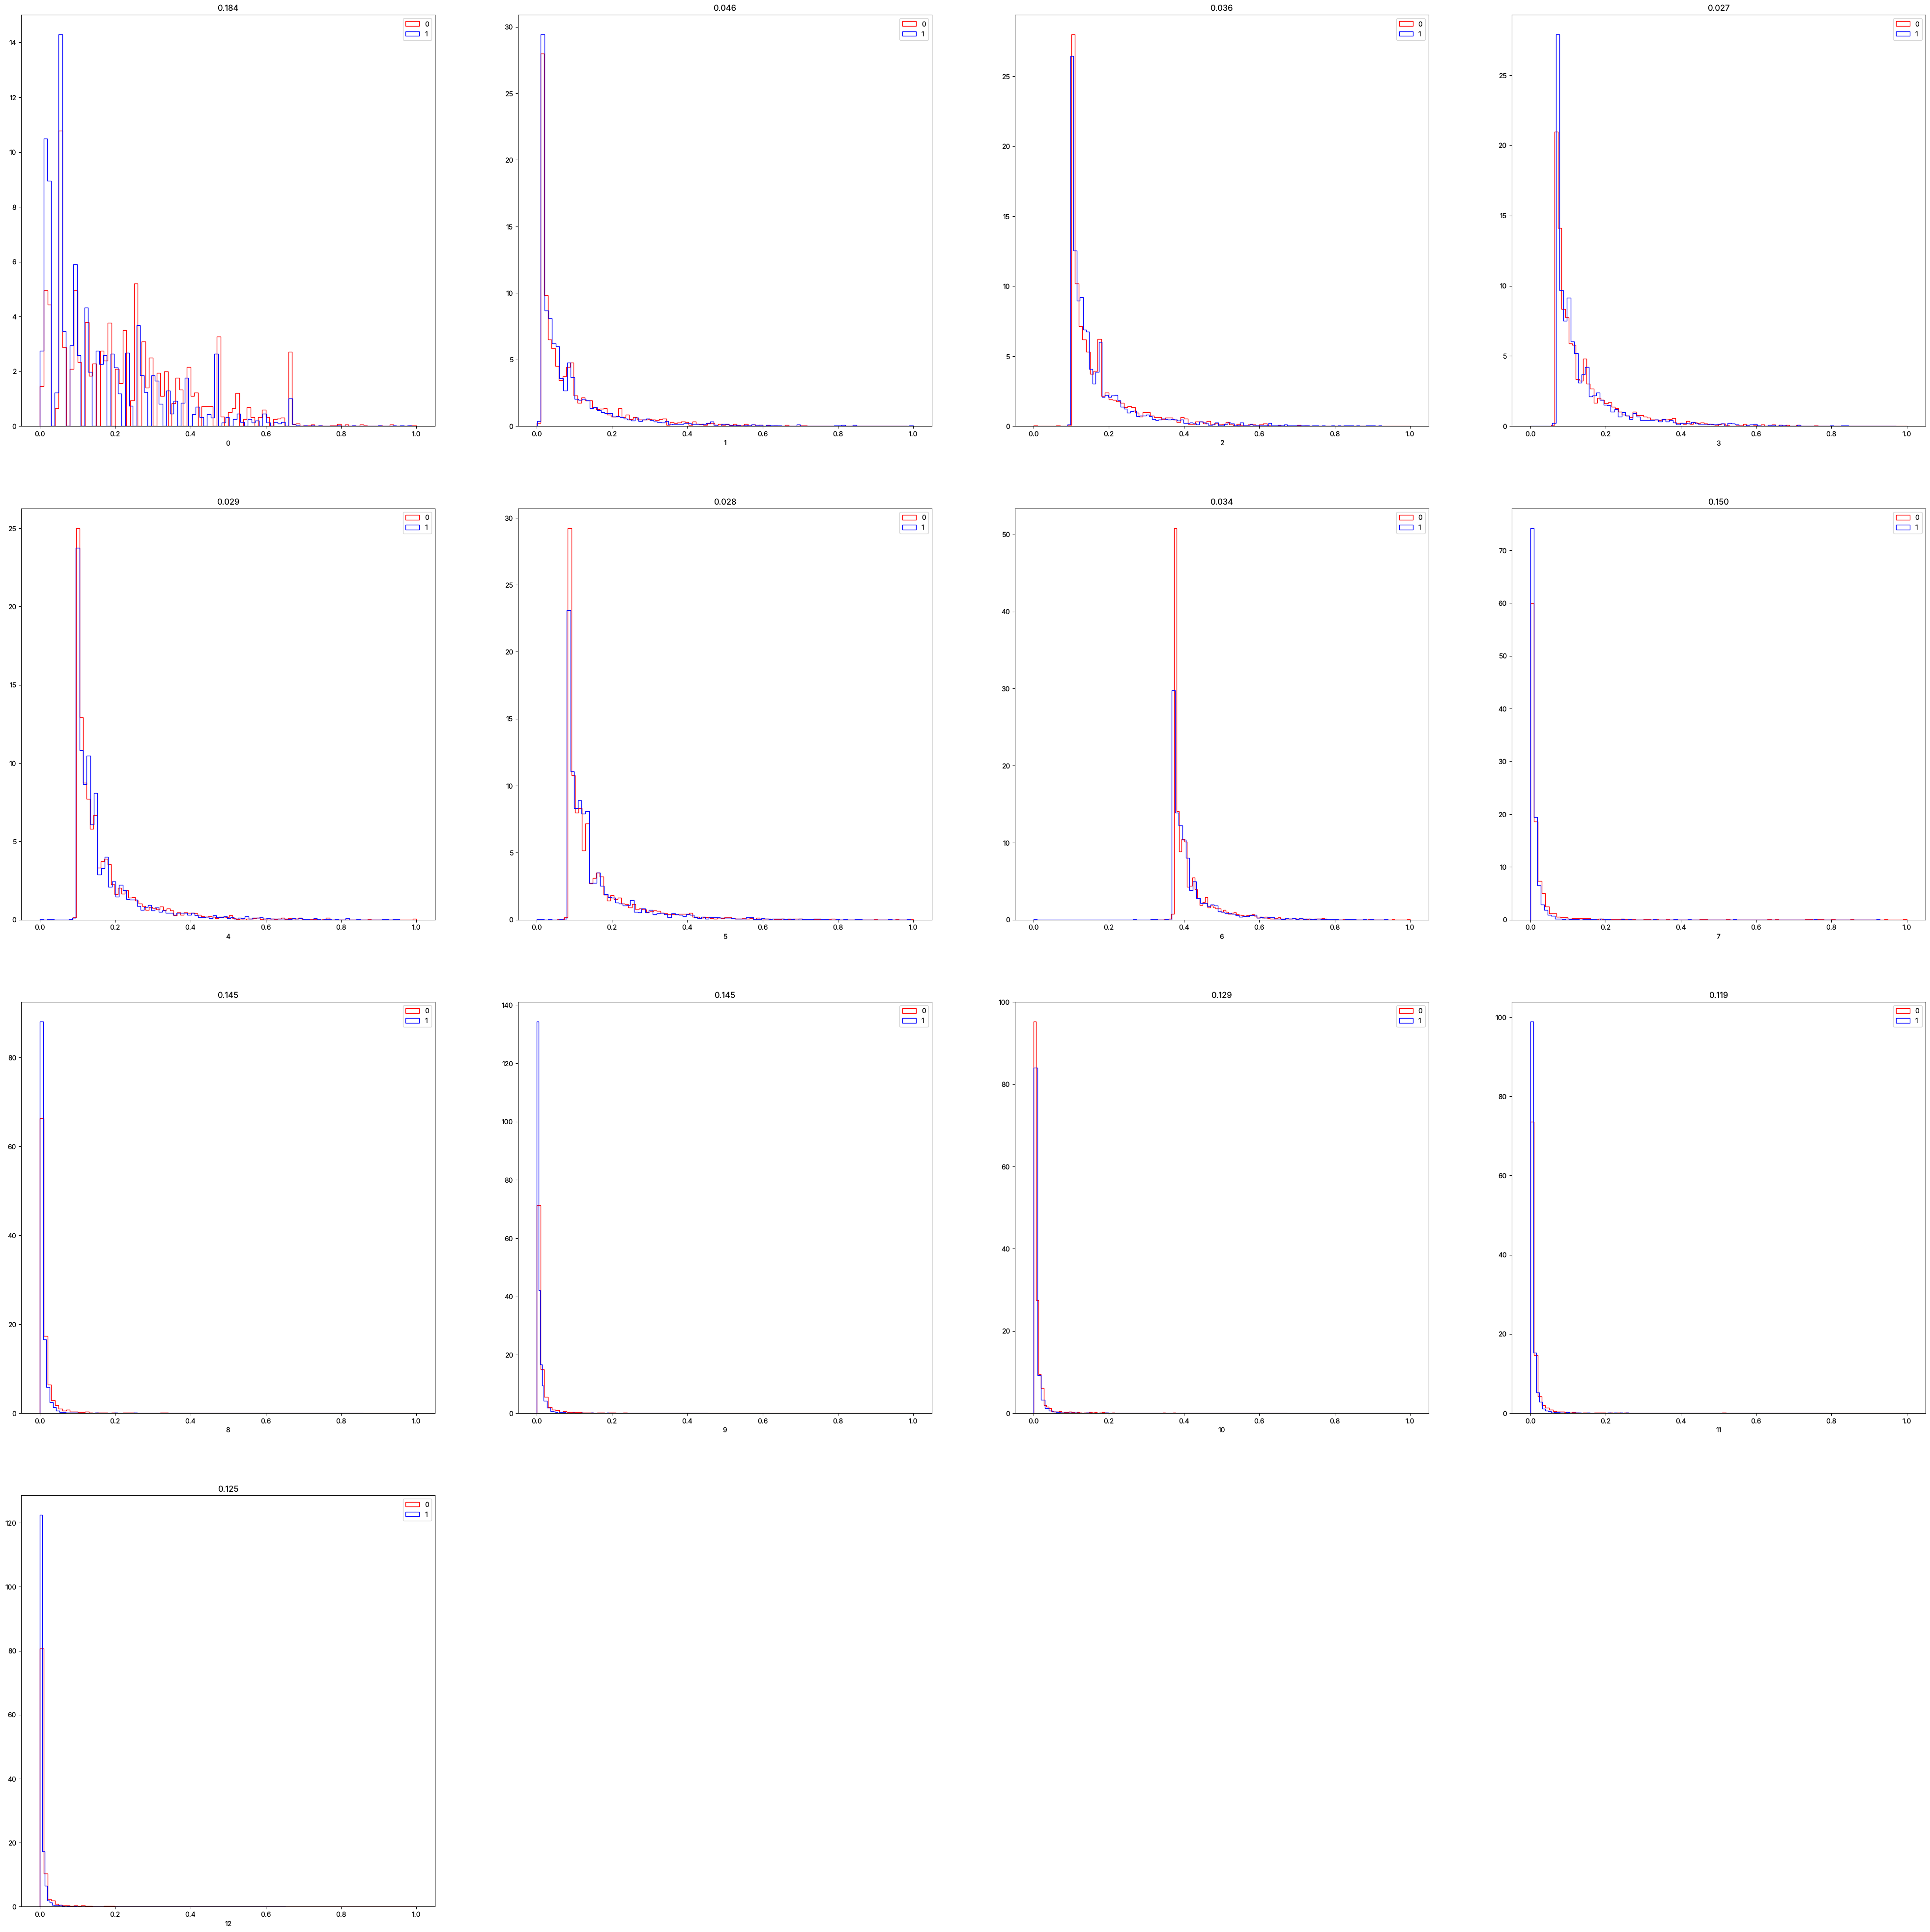

In [76]:
compare_features_binary(d1,logscale=False)

Always check after scaling that the scaling did what you meant. Here the histograms keep their
shapes and the KS values are the same as before scaling: min-max scaling only stretches each axis,
and KS doesn't care. (The column names are now the integers 0–12, because the scaled array was put back into a
DataFrame without names.)

In [77]:
d1["Training"].shape

(7963, 13)

In [78]:
# Fixed 2026-10: number the columns 0-130 (the two frames both had columns 0, 1, 2, ..., and
# recent scikit-learn refuses repeated column names)
training_data = pd.concat([d1["Training"],encoded],axis=1,ignore_index=True)

In [79]:
d1["Training"]=training_data

In [80]:
d1["Training"]

,0,1,2,3,4,5,6,7,8,9,...,121,122,123,124,125,126,127,128,129,130
0,0.027027,0.055603,0.146180,0.118117,0.147523,0.125050,0.398961,0.006192,0.004489,0.000000,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.054054,0.096687,0.179992,0.149849,0.146443,0.134752,0.405820,0.000000,0.000000,0.000000,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.405405,0.010429,0.169678,0.102677,0.227679,0.120891,0.402093,0.140811,0.049957,0.190427,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.189189,0.199713,0.232333,0.138564,0.167108,0.157383,0.421769,0.015498,0.007481,0.003477,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.148649,0.068678,0.141169,0.102362,0.104648,0.091515,0.376390,0.004415,0.015960,0.003592,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7958,0.054054,0.011405,0.103263,0.071677,0.102754,0.087657,0.373913,0.000000,0.000000,0.000000,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7959,0.054054,0.015327,0.103263,0.071983,0.107477,0.119929,0.373913,0.000000,0.000491,0.007172,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7960,0.000000,0.026635,0.117402,0.083075,0.116985,0.100698,0.383142,0.003427,0.003267,0.004789,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7961,0.054054,0.089483,0.173153,0.089004,0.098187,0.167383,0.426932,0.007740,0.007486,0.003592,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


13 scaled numerical columns plus 118 one-hot columns: 131. Both frames had columns numbered from 0,
so joining them side by side repeated the labels 0–12. **Corrected 2026-10:** `ignore_index=True`
numbers the columns 0–130, because recent versions of scikit-learn refuse repeated column names.

## Trying ML Algorithm



In [81]:
d1["Training"].shape

(7963, 131)

In [82]:
import math

N_total = d1["Training"].shape[0]
N_train = math.floor(.8*N_total)
N_val = math.floor((N_total-N_train)/2.)
N_test = math.floor((N_total-N_train)/2.)

X_train = d1["Training"][:N_train]
Y_train = d1["Target"][:N_train]

X_val = d1["Training"][N_train:N_val+N_train]
Y_val = d1["Target"][N_train:N_val+N_train]
                     
X_test = d1["Training"][N_train+N_val:N_test+N_val+N_train]
Y_test = d1["Target"][N_train+N_val:N_test+N_val+N_train]

N_val

796

Splitting is slicing: 80% for training, 10% for **validation** (for choosing among models and
settings), 10% for test (for the final, unbiased number). scikit-learn's
`train_test_split` does nothing fancier, apart from shuffling, and the benchmark's rows are already
shuffled.

In [83]:
import sklearn.discriminant_analysis as DA
# Instanciate Method
Fisher=DA.LinearDiscriminantAnalysis()

In [84]:
Fisher.fit(X_train,Y_train)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide ` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None


In [85]:
Fisher.predict(X_val.to_numpy())

array([0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1,
       0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1,
       1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0,
       0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1,
       0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0,
       1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0,

As in the scikit-learn lecture: `predict` cuts the output at zero. Look at the output itself instead.

In [86]:
X_val_0 = X_val[Y_val.to_numpy()==0]
X_val_1 = X_val[Y_val.to_numpy()==1]

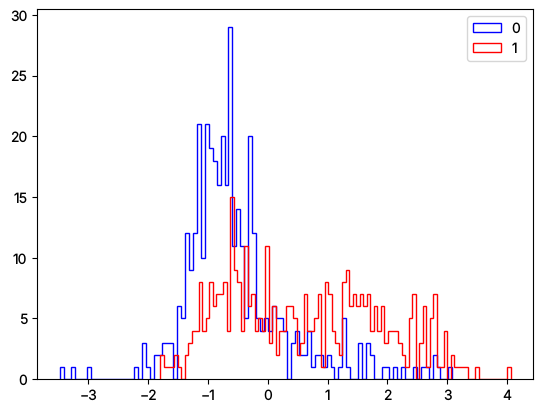

In [87]:
plt.figure()
plt.hist(Fisher.decision_function(X_val_0.to_numpy()),bins=100,histtype="step", color="blue", label="0",stacked=True)
plt.hist(Fisher.decision_function(X_val_1.to_numpy()),bins=100,histtype="step", color="red", label="1",stacked=True)
plt.legend(loc='upper right')
plt.show()

Select only the examples with a high output and the sample is much richer in class 1 than the whole:
the improvement in **signal-to-noise** that the ROC curve below traces, threshold by threshold. (This
histogram uses the validation rows; the ROC curve uses the test rows.)

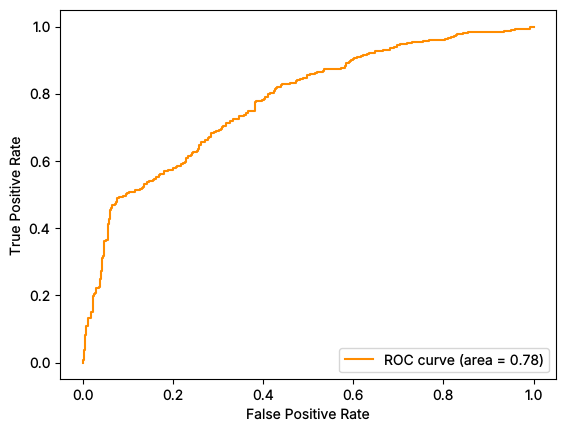

In [88]:
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(Y_test.to_numpy(), Fisher.decision_function(X_test.to_numpy()))

roc_auc = auc(fpr, tpr)

plt.plot(fpr,tpr,color='darkorange',label='ROC curve (area = %0.2f)' % roc_auc)
plt.legend(loc="lower right")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.show()

About 80% true positive rate at about 40% false positive rate, AUC 0.78: not great, but OK, from 796
test events. One-hot encoding helped: with each category in its own column, a linear model can give
each category its own weight. On the raw 21 columns the same LDA reaches an AUC of about 0.72 (rescaling makes no difference to LDA).

**This is your baseline.** Before anything fancy, train something simple and quick, like LDA or a
logistic regression. If a fancier method then does worse than the baseline, something is wrong.

A **baseline** is the performance you expect before you try anything clever. It can come from a crude
estimate ("using this one feature I can give 60% accuracy if I'm being really dumb"), from other
people's published results on similar data, or from the histograms above: if some features clearly
differ between the classes, a simple classifier should find some separation. Make it simple and fast,
because when a simple model fails there are few places to look; when a deep network fails, you can't
tell whether the data or "all these complicated things that I did" is to blame. With a baseline in
hand, a poor result points at your method, not at the data.

## Comparing ML Algorithms

In [89]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier



In [90]:
names = [
    "Nearest Neighbors",
    "Linear SVM",
    "RBF SVM",
#     "Gaussian Process",
#     "Decision Tree",
#     "Random Forest",
#     "Neural Net",
#     "AdaBoost",
#     "Naive Bayes",
#     "QDA",
]
classifier_instances = [
    KNeighborsClassifier(3),
    SVC(kernel="linear", C=0.025, random_state=42),
    SVC(gamma=2, C=1, random_state=42),
#     GaussianProcessClassifier(1.0 * RBF(1.0), random_state=42),
#     DecisionTreeClassifier(max_depth=5, random_state=42),
#     RandomForestClassifier(
#         max_depth=5, n_estimators=10, max_features=1, random_state=42
#     ),
#     MLPClassifier(alpha=1, max_iter=1000, random_state=42),
#     AdaBoostClassifier(algorithm="SAME", random_state=42),
#     GaussianNB(),
#     QuadraticDiscriminantAnalysis(),
]
classifiers = dict(zip(names,classifier_instances))

This comparison is adapted from scikit-learn's "Classifier comparison" example in its documentation
gallery (the classifier settings and the 60/40 split with `random_state=42` come from there). Only
three classifiers are switched on, to keep the run short. Note that `gamma=2` for the RBF SVM was
chosen in that example for two-dimensional toy data; on another dataset it may be far from the best
setting, which is a hyperparameter you would tune on validation data.

In [91]:
datasets = { name : (d["Training"],d["Target"]) for name , d in [(name , load_dataset(name)) for name in binary_classification_datasets]}

In [92]:
classifiers.keys()

dict_keys(['Nearest Neighbors', 'Linear SVM', 'RBF SVM'])

In [93]:
#figure = plt.figure(figsize=(27, 9))
# iterate over datasets
import sys

def fit_all(datasets,classifiers, max_ds=None, max_cls=None):
    scores = dict()
    for ds_cnt, (ds_name,ds) in enumerate(datasets.items()):
        # preprocess dataset, split into training and test part
        X, y = ds
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.4, random_state=42
        )

        if max_ds:
            if ds_cnt>max_ds:
                print("Max Datasets Reached.")
                sys.stdout.flush()
                break
                
        scores[ds_name] = dict()
        # iterate over classifiers
        for cls_cnt,(cls_name, clf) in enumerate(classifiers.items()):
            print(ds_cnt,cls_cnt,"Running classifier",cls_name,"on dataset",ds_name,". N_Train = ",X_train.shape[0] )
            sys.stdout.flush()
            clf_0 = make_pipeline(StandardScaler(), clf)
            clf_0.fit(X_train.to_numpy(), y_train.to_numpy().reshape((len(y_train),)))
            # Fixed 2026-10: score the pipeline that was fit (scaler + classifier), not the bare classifier
            score = clf_0.score(X_test.to_numpy(), y_test.to_numpy())

            scores[ds_name][cls_name] = score
            if max_cls:
                if cls_cnt>max_cls:
                    print("Max Classifiers Reached.")
                    sys.stdout.flush()
                    break


    return scores
        

#plt.tight_layout()
#plt.show()

**Corrected 2026-10.** The line that scores each classifier used to read
`score = clf.score(X_test.to_numpy(), y_test.to_numpy())`. `make_pipeline` does not copy `clf`: the
pipeline `clf_0` contains that same object, so `clf_0.fit` standardized the training features and
fitted `clf` on them. Scoring `clf` alone then fed it the **raw**, unstandardized test features. In the
run shown in class, which took the credit dataset first, a credit limit of 100,000 was far outside
anything the classifier saw in training, so its predictions collapsed to one class and the scores sat
near chance. The fix scores the pipeline, which standardizes the test
features the same way.

A **pipeline** chains steps, here a scaler and then a classifier. Calling `fit` on the pipeline fits
each step in turn and passes the transformed data along; `score` and `predict` push new data through
the same steps. For a classifier, `score` is the **accuracy**, the fraction of test examples labelled
correctly. Accuracy only means something against **chance**: with balanced classes guessing scores
0.5, but with 90% of one class, always guessing that class scores 0.9.

Why can one loop handle any classifier? Every scikit-learn model shares a base class and the same
methods, `fit` and `score`: polymorphism, as in Chapter 4.

(The limits `max_ds` and `max_cls` are checked one step late, so `fit_all(datasets, classifiers, 1, 2)`
runs two datasets and all three classifiers.)

In [94]:
scores = fit_all(datasets,classifiers,1,2)

0 0 Running classifier Nearest Neighbors on dataset 334_361110 . N_Train =  13850
0 1 Running classifier Linear SVM on dataset 334_361110 . N_Train =  13850
0 2 Running classifier RBF SVM on dataset 334_361110 . N_Train =  13850
1 0 Running classifier Nearest Neighbors on dataset 334_361111 . N_Train =  2738
1 1 Running classifier Linear SVM on dataset 334_361111 . N_Train =  2738
1 2 Running classifier RBF SVM on dataset 334_361111 . N_Train =  2738
Max Datasets Reached.


In [95]:
scores

{'334_361110': {'Nearest Neighbors': 0.8008447043534763,
  'Linear SVM': 0.7400909681611436,
  'RBF SVM': 0.819254927442062},
 '334_361111': {'Nearest Neighbors': 0.5454545454545454,
  'Linear SVM': 0.5662650602409639,
  'RBF SVM': 0.4994523548740416}}

In [96]:
display(HTML(tabulate.tabulate(list(map(lambda x: [x[0]]+x[1],zip(scores.keys(),map(lambda x: list(x.values()),scores.values())))), 
                               tablefmt='html',
                               headers=[" "]+list(next(iter(scores.items()))[1].keys()))))

,Nearest Neighbors,Linear SVM,RBF SVM
334_361110,0.800845,0.740091,0.819255
334_361111,0.545455,0.566265,0.499452


## Reading the comparison

`fit_all` ran on the first two binary datasets in name order: `334_361110` (**electricity**: will the
price go up or down) and `334_361111` (**eye_movements**: whether a sentence was relevant to a question,
from the reader's eye movements). On electricity the three classifiers reach accuracies of about 0.80, 0.74 and 0.82.
On eye_movements (whose two classes are equally common, so guessing scores 0.5) they reach only 0.55,
0.57 and 0.50: a genuinely hard dataset for these methods, and a reminder to compare against a
baseline. The RBF SVM at exactly chance is the `gamma=2` point made above.

**The lesson of the bug.** Before the scoring fix, this comparison showed every classifier near
chance. In the run shown in class, which took the credit dataset and albert, the scores were 0.50 on
credit and 0.50–0.58 on albert. The suspects were the encoding and the scaling; the real cause was the
scoring line. The LDA baseline above had already reached an AUC of 0.78 on credit, so scores of 0.50
there should have been a red flag. Use whatever tools you like, but understand what they are
doing, look at the results, and check you got what you expected. Don't do it blindly.

**Why this machinery exists.** Much of the work in machine learning is comparison: different
algorithms, different settings of one algorithm, different ways of preparing the data. Settings you
choose rather than learn, such as `C`, `gamma`, `n_neighbors` or a learning rate, are
**hyperparameters**, and searching them can mean training dozens or hundreds of models. A common
interface makes that bookkeeping manageable. Writing the loops out by hand works just as well, and
every step is then visible. The same class can appear twice in `classifiers` with different settings.

**What your project needs.** At minimum, one algorithm that gets a **non-trivial** result: clearly
better than chance and than your baseline. Trying two or three is easy, because only the class name
changes. For your project, add the method the paper recommends: gradient-boosted trees
(`HistGradientBoostingClassifier` in scikit-learn, or XGBoost). Once a notebook grows this large,
move the helper functions (`load_dataset`, `compare_features_binary`, `fit_all`) into a module of
their own, which is where the lecture on tabular data with Keras picks up. A notebook this size is a
scratch pad. A tidier project uses one notebook for each stage: visualization, then preparation, then
one notebook per algorithm, each writing its results to a file, and a final notebook that loads them
all and compares. Code that more than one notebook needs goes into the module they import.